# 03. Центральная fusion-модель на raw multi-rate наборе окон

Этот notebook продолжает цепочку `01 -> 02 -> 03`. В первых двух notebook были изучены исходные данные и собран итоговый multi-rate набор окон. На вход текущему этапу передаются два файла из notebook `02`: основной CSV с согласованными окнами и краткий JSON-отчёт о его параметрах.

В этом notebook окна не пересобираются, целевые переменные не меняются, а train/test-разбиение принимается из предыдущего этапа. Задача здесь другая: проверить, можно ли поверх уже подготовленного набора данных построить центральную мультимодальную модель, которая использует несколько источников информации одновременно.

Модель будет работать с тремя группами признаков. Первая группа — текст логов, который переводится в embedding-представление с помощью внешнего encoder. Вторая группа — числовые признаки логов на micro- и macro-окнах. Третья группа — KPI-признаки, которые сохраняют структуру временных рядов через представление «ряд × статистика».

Так как не каждое окно содержит одновременно и логи, и KPI, модель не должна просто склеивать все признаки в одну таблицу. Поэтому используется late fusion: сначала отдельные ветви обрабатывают свои группы признаков, затем их представления объединяются с учётом масок доступности модальностей. Это позволяет явно учитывать ситуацию, когда одна из модальностей отсутствует.

Важно, что результаты этого notebook следует рассматривать как экспериментальную проверку центральной fusion-архитектуры. Разметка отказов остаётся proxy-разметкой из notebook `02`, поэтому метрики полного обучения не должны интерпретироваться как окончательное промышленное качество модели.

## 1. Исходные решения для модели

В notebook `02` был получен набор окон, где каждое наблюдение связано с конкретным запуском, временным окном, логовыми признаками, KPI-признаками, масками доступности и двумя целевыми переменными: `y_warning` и `y_risk`.

Для текущей модели важны не все технические детали предыдущего этапа, а только те решения, которые влияют на обучение:

| Что приходит из notebook `02` | Как это используется в notebook `03` |
|---|---|
| Готовая оконная сетка | окна не пересобираются |
| Колонка `split` | train/test-разбиение не создаётся заново |
| `run_id` | validation отделяется с учётом запусков |
| `log_text` | используется для embedding-представления логов |
| log micro/macro признаки | подаются в отдельные числовые ветви |
| KPI-статистики в колонках `kpi_*__stat` | собираются в KPI-тензор |
| признаки доступности модальностей | используются как маски для fusion-блока |
| `y_warning`, `y_risk` | используются как две связанные целевые переменные |

Архитектура строится как центральная fusion-модель: логовая ветвь, KPI-ветвь и блок объединения представлений. Такой вариант выбран потому, что простая табличная модель хуже отражает структуру данных: текст логов, агрегаты логов и KPI-ряды имеют разную природу и разную степень доступности.

В текущем notebook есть два режима работы. На локальном ноутбуке используется режим отладки: он нужен, чтобы быстро проверить загрузку данных, подготовку признаков и один проход через модель. На машине для обучения включается полный режим, где выполняется обучение, оценка и сохранение итоговых результатов.

In [29]:
import os

os.environ["HF_HUB_DISABLE_XET"] = "1"
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "120"
os.environ["HF_HUB_ETAG_TIMEOUT"] = "120"

In [30]:
from huggingface_hub import snapshot_download

path = snapshot_download(
    repo_id="google/embeddinggemma-300m",
    token=True,
    max_workers=1,
)

print(path)

Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

C:\Users\а\.cache\huggingface\hub\models--google--embeddinggemma-300m\snapshots\57c266a740f537b4dc058e1b0cda161fd15afa75


In [31]:
# Режим запуска:
# "debug" — локальный ноутбук, быстрая проверка кода и формы данных
# "train" — машина для полного обучения модели

RUN_MODE = "train"  # поменять на "debug" для быстрой локальной проверки

MODE_CONFIG = {
    "debug": {
        "run_full_training": False,
        "max_debug_rows": 1500,
        "allow_hf_download": False,
        "hf_embed_batch_size": 16,
        "batch_size": 64,
        "dry_run_batch_size": 32,
        "max_epochs": 3,
        "text_profile": "short",
        "embedding_truncate_dim": 128,
        "embedding_ablation_dims": [128],
        "train_seeds": [42],
        "run_architecture_ablation": False,
        "risk_recall_target": 0.80,
    },
    "train": {
        "run_full_training": True,
        "max_debug_rows": None,
        "allow_hf_download": True,
        "hf_embed_batch_size": 64,
        "batch_size": 128,
        "dry_run_batch_size": 64,
        "max_epochs": 120,
        "text_profile": "balanced",
        "embedding_truncate_dim": 256,
        "embedding_ablation_dims": [128, 256, 512, 768],
        "train_seeds": [42, 43, 44],
        "run_architecture_ablation": True,
        "risk_recall_target": 0.80,
    },
}

if RUN_MODE not in MODE_CONFIG:
    raise ValueError("RUN_MODE должен быть 'debug' или 'train'")

CFG = MODE_CONFIG[RUN_MODE]


In [32]:
from pathlib import Path
import gc
import hashlib
import json
import math
import os
import random
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
import re
import time


import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    precision_recall_fscore_support,
    roc_auc_score,
)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset

try:
    import joblib
except Exception:
    joblib = None


pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 160)
warnings.filterwarnings("ignore", category=RuntimeWarning)

HF_MIRROR = os.getenv("HF_MIRROR", "").strip()

if HF_MIRROR:
    HF_MIRROR = HF_MIRROR.rstrip("/")
    os.environ["HF_MIRROR"] = HF_MIRROR
    os.environ["HF_ENDPOINT"] = HF_MIRROR

HF_ENDPOINT = os.getenv("HF_ENDPOINT", "").strip() or None


ROOT = Path.cwd()

# Реальные входы из notebook 02
CONTRACT_PATH = ROOT / "outputs" / "raw_multirate" / "aligned_multirate_windows.csv"
BASELINE_SUMMARY_PATH = ROOT / "outputs" / "raw_multirate" / "baseline_summary_metrics.json"

# Выходы текущего notebook
OUT_ROOT = ROOT / "outputs" / "raw_central_model"
CACHE_DIR = OUT_ROOT / "cache"
OUT_ROOT.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)


SEED = 42

RUN_FULL_TRAINING = CFG["run_full_training"]
MAX_DEBUG_ROWS = CFG["max_debug_rows"]
ALLOW_HF_DOWNLOAD = CFG["allow_hf_download"]
HF_EMBED_BATCH_SIZE = CFG["hf_embed_batch_size"]
BATCH_SIZE = CFG["batch_size"]
DRY_RUN_BATCH_SIZE = CFG["dry_run_batch_size"]
MAX_EPOCHS = CFG["max_epochs"]

HF_GOOGLE_EMBEDDER_MODEL = "google/embeddinggemma-300m"
HASHING_FALLBACK_DIM = 192
TEXT_PROFILE_MAX_CHARS = {"short": 512, "balanced": 768, "full": 1400}
TEXT_PROFILE = CFG["text_profile"]
if TEXT_PROFILE not in TEXT_PROFILE_MAX_CHARS:
    raise ValueError(f"Неизвестный text_profile: {TEXT_PROFILE}")
TEXT_MAX_CHARS = int(TEXT_PROFILE_MAX_CHARS[TEXT_PROFILE])
TEXT_NORMALIZER_VERSION = "signal-log-v2"
EMBEDDING_TRUNCATE_DIM = int(CFG["embedding_truncate_dim"])
EMBEDDING_ABLATION_DIMS = [int(dim) for dim in CFG["embedding_ablation_dims"]]
TRAIN_SEEDS = [int(seed) for seed in CFG["train_seeds"]]
RUN_ARCHITECTURE_ABLATION = bool(CFG["run_architecture_ablation"])
RISK_RECALL_TARGET = float(CFG["risk_recall_target"])
MONITOR_WEIGHTS = {"ap_warning": 0.40, "ap_risk": 0.40, "risk_recall": 0.20}

HIDDEN_DIM = 64
PATIENCE = 14
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
MODALITY_DROPOUT = 0.20

LAMBDA_RISK = 0.75
LAMBDA_AUX = 0.12
USE_AUX_HEADS = True


STAT_ORDER = ["mean", "last", "std", "delta", "slope"]

LOG_MACRO_COLS = [
    "macro_log_count",
    "macro_unique_components",
    "macro_warn_count",
    "macro_error_count",
    "macro_keyword_count",
    "macro_log_rate",
]

LOG_MICRO_COLS = [
    "micro_log_count",
    "micro_unique_components",
    "micro_warn_count",
    "micro_error_count",
    "micro_keyword_count",
    "micro_log_rate",
    "micro_error_rate",
]

MODEL_MASK_COLS = [
    "log_available",
    "kpi_available",
    "has_both_modalities",
    "kpi_avail_ratio",
]

KPI_MICRO_COLS = [
    "kpi_series_available",
    "kpi_feature_count",
    "kpi_avail_ratio",
    "kpi_recency_sec",
]

TARGET_COLS = ["y_warning", "y_risk"]


def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def json_sanitize(obj):
    if isinstance(obj, dict):
        return {str(k): json_sanitize(v) for k, v in obj.items()}

    if isinstance(obj, (list, tuple)):
        return [json_sanitize(v) for v in obj]

    if isinstance(obj, np.integer):
        return int(obj)

    if isinstance(obj, np.floating):
        value = float(obj)
        return value if math.isfinite(value) else None

    if isinstance(obj, float):
        return obj if math.isfinite(obj) else None

    if isinstance(obj, np.bool_):
        return bool(obj)

    if obj is pd.NA:
        return None

    return obj


def write_json_safe(path: Path, payload: dict) -> None:
    with Path(path).open("w", encoding="utf-8") as f:
        json.dump(
            json_sanitize(payload),
            f,
            ensure_ascii=False,
            indent=2,
            allow_nan=False,
        )


def finite_float(value):
    try:
        value = float(value)
    except Exception:
        return None

    return value if math.isfinite(value) else None


set_seed(SEED)

setup_summary = pd.DataFrame(
    [
        {"Параметр": "Режим запуска", "Значение": RUN_MODE},
        {"Параметр": "Полное обучение", "Значение": RUN_FULL_TRAINING},
        {"Параметр": "Максимум строк в debug", "Значение": MAX_DEBUG_ROWS},
        {"Параметр": "Текстовый encoder", "Значение": HF_GOOGLE_EMBEDDER_MODEL},
        {"Параметр": "Профиль log_text", "Значение": TEXT_PROFILE},
        {"Параметр": "Максимум символов log_text", "Значение": TEXT_MAX_CHARS},
        {"Параметр": "Embedding truncate_dim", "Значение": EMBEDDING_TRUNCATE_DIM},
        {"Параметр": "Train seeds", "Значение": TRAIN_SEEDS},
        {"Параметр": "Выходная папка", "Значение": str(OUT_ROOT.relative_to(ROOT))},
    ]
)

setup_summary

,Параметр,Значение
0,Режим запуска,train
1,Полное обучение,True
2,Максимум строк в debug,None
3,Текстовый encoder,google/embeddinggemma-300m
4,Профиль log_text,balanced
5,Максимум символов log_text,768
6,Embedding truncate_dim,256
7,Train seeds,"[42, 43, 44]"
8,Выходная папка,outputs\raw_central_model


## 2. Загрузка и валидация strict-контракта

Этот блок читает только артефакты из `outputs/raw_multirate/`. Если contract или schema отсутствуют, ноутбук останавливается сразу: silent fallback на старые результаты запрещён.


### 2.1. Загрузка данных и базовые проверки

Эта ячейка читает итоговый CSV из notebook `02` и выполняет только те проверки, которые нужны перед построением модели. Подробные служебные таблицы не выводятся: если проверка не проходит, notebook показывает проблемное место и останавливается.

In [33]:
from IPython.display import Markdown, display
import matplotlib.pyplot as plt


def require_file(path, label):
    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(
            f"Не найден файл {path}. Сначала необходимо выполнить notebook 02: {label}"
        )


# На случай, если в предыдущей ячейке путь был назван по-разному.
if "BASELINE_SUMMARY_PATH" not in globals():
    BASELINE_SUMMARY_PATH = globals().get(
        "BASELINE_METRICS_PATH",
        ROOT / "outputs" / "raw_multirate" / "baseline_summary_metrics.json",
    )

BASELINE_SUMMARY_PATH = Path(BASELINE_SUMMARY_PATH)


# Входы notebook 03.
require_file(CONTRACT_PATH, "итоговый multi-rate набор окон")
require_file(BASELINE_SUMMARY_PATH, "краткий отчёт notebook 02")

with BASELINE_SUMMARY_PATH.open("r", encoding="utf-8") as f:
    baseline_summary = json.load(f)


df = pd.read_csv(CONTRACT_PATH, low_memory=False)
df["log_text"] = df["log_text"].fillna("").astype(str)


# В notebook 03 split не восстанавливается заново.
split_fallback_used = False
split_fallback_reason = None


required_cols = [
    "workload",
    "scenario",
    "run_id",
    "window_ts",
    "split",
    "log_text",
    "micro_window_sec",
    "macro_window_sec",
    "strict_path_pair",
    "anchor_policy",
    "minutes_before_fail",
    "y_warning",
    "y_risk",
    "log_available",
    "kpi_available",
    "has_both_modalities",
    "kpi_avail_ratio",
    "kpi_series_available",
    "kpi_feature_count",
    "kpi_recency_sec",
] + LOG_MACRO_COLS + LOG_MICRO_COLS

missing_required = [col for col in required_cols if col not in df.columns]

if missing_required:
    raise ValueError(
        "В итоговом наборе окон отсутствуют обязательные колонки: "
        f"{missing_required[:20]}"
    )


# Проверка split.
df["split"] = df["split"].astype(str).str.lower()
unexpected_splits = sorted(set(df["split"].unique()) - {"train", "test"})

if unexpected_splits:
    raise ValueError(f"В колонке split найдены неожиданные значения: {unexpected_splits}")


# Проверка strict-строк.
strict_values = df["strict_path_pair"].map(
    lambda value: str(value).strip().lower() in {"true", "1", "yes"}
)

non_strict_rows = int((~strict_values).sum())

if non_strict_rows:
    raise ValueError(
        f"В наборе для notebook 03 обнаружены non-strict строки: {non_strict_rows}"
    )


# Проверка повторяющихся окон.
duplicate_key_count = int(
    df.duplicated(["run_id", "window_ts", "micro_window_sec"]).sum()
)

if duplicate_key_count:
    raise ValueError(
        "Найдены повторяющиеся окна по ключу "
        f"(run_id, window_ts, micro_window_sec): {duplicate_key_count}"
    )


# Проверка целевых переменных и масок.
critical_numeric_cols = [
    "y_warning",
    "y_risk",
    "log_available",
    "kpi_available",
    "has_both_modalities",
    "kpi_avail_ratio",
    "kpi_series_available",
    "kpi_feature_count",
]

for col in critical_numeric_cols:
    df[col] = (
        pd.to_numeric(df[col], errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
    )

bad_numeric = {
    col: int(df[col].isna().sum())
    for col in critical_numeric_cols
    if int(df[col].isna().sum()) > 0
}

if bad_numeric:
    raise ValueError(f"В целевых переменных или масках есть пропуски: {bad_numeric}")


binary_cols = [
    "y_warning",
    "y_risk",
    "log_available",
    "kpi_available",
    "has_both_modalities",
]

for col in binary_cols:
    values = set(df[col].astype(int).unique())

    if not values.issubset({0, 1}):
        raise ValueError(f"Колонка {col} должна содержать только значения 0/1")

    df[col] = df[col].astype(int)


if not df["kpi_avail_ratio"].between(0, 1).all():
    raise ValueError("Колонка kpi_avail_ratio должна находиться в диапазоне [0, 1]")


# kpi_recency_sec используется как числовой признак.
# Если там есть единичные пропуски, заменяем их максимальным наблюдаемым значением.
recency_raw = (
    pd.to_numeric(df["kpi_recency_sec"], errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
)

recency_missing_count = int(recency_raw.isna().sum())

if recency_missing_count:
    recency_fill_value = float(recency_raw.max()) if recency_raw.notna().any() else 0.0
    df["kpi_recency_sec"] = recency_raw.fillna(recency_fill_value).astype(float)
else:
    recency_fill_value = None
    df["kpi_recency_sec"] = recency_raw.astype(float)


# Проверка наличия двух классов в train/test.
class_presence = []

for split_name, part in df.groupby("split"):
    for target in TARGET_COLS:
        counts = part[target].astype(int).value_counts().to_dict()

        class_presence.append(
            {
                "split": split_name,
                "target": target,
                "negatives": int(counts.get(0, 0)),
                "positives": int(counts.get(1, 0)),
                "both_classes": part[target].nunique() == 2,
            }
        )

class_presence_df = pd.DataFrame(class_presence)

failed_class_checks = class_presence_df[
    (class_presence_df["split"].isin(["train", "test"]))
    & (~class_presence_df["both_classes"])
]

if not failed_class_checks.empty:
    display(failed_class_checks)

    raise ValueError(
        "В одном из split отсутствует положительный или отрицательный класс "
        "для одной из целевых переменных"
    )


contract_summary = {
    "rows": int(len(df)),
    "columns": int(df.shape[1]),
    "runs": int(df["run_id"].nunique()),
    "workloads": int(df["workload"].nunique()),
    "duplicate_windows": duplicate_key_count,
    "y_warning_share": float(df["y_warning"].mean()),
    "y_risk_share": float(df["y_risk"].mean()),
    "kpi_available_share": float(df["kpi_available"].mean()),
    "both_modalities_share": float(df["has_both_modalities"].mean()),
    "kpi_recency_imputed": recency_missing_count,
}

split_summary = (
    df.groupby("split")
    .agg(
        rows=("run_id", "size"),
        runs=("run_id", "nunique"),
        workloads=("workload", "nunique"),
        y_warning_share=("y_warning", "mean"),
        y_risk_share=("y_risk", "mean"),
        log_available_share=("log_available", "mean"),
        kpi_available_share=("kpi_available", "mean"),
        both_modalities_share=("has_both_modalities", "mean"),
    )
    .reset_index()
)


summary_text = f"""
**Итоговый набор окон загружен успешно.**

- строк: **{contract_summary["rows"]:,}**
- запусков: **{contract_summary["runs"]:,}**
- workloads: **{contract_summary["workloads"]:,}**
- доля `y_warning = 1`: **{contract_summary["y_warning_share"]:.3f}**
- доля `y_risk = 1`: **{contract_summary["y_risk_share"]:.3f}**
- доля окон с обеими модальностями: **{contract_summary["both_modalities_share"]:.3f}**
- повторяющихся окон: **{contract_summary["duplicate_windows"]}**
- заполненных пропусков в `kpi_recency_sec`: **{contract_summary["kpi_recency_imputed"]}**
"""

Markdown(summary_text)


**Итоговый набор окон загружен успешно.**

- строк: **10,237**
- запусков: **440**
- workloads: **16**
- доля `y_warning = 1`: **0.293**
- доля `y_risk = 1`: **0.123**
- доля окон с обеими модальностями: **0.568**
- повторяющихся окон: **0**
- заполненных пропусков в `kpi_recency_sec`: **4**


### 2.2. Баланс целевых переменных в train/test

Следующий график показывает, насколько близки доли положительного класса в обучающей и тестовой частях. Это важно для дальнейшей оценки модели: если одна из частей содержит сильно другую долю предупреждений или рисковых окон, метрики могут отражать не только качество модели, но и отличие распределений между split.

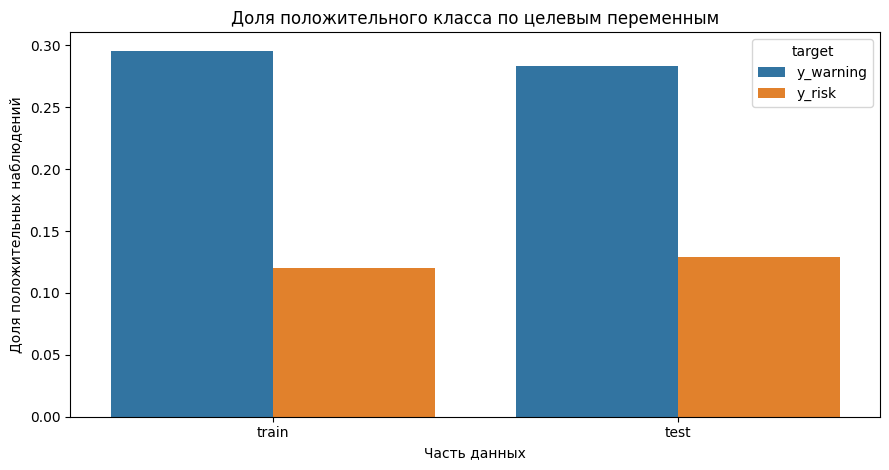

In [34]:
plot_df = (
    split_summary[
        ["split", "y_warning_share", "y_risk_share"]
    ]
    .rename(
        columns={
            "y_warning_share": "y_warning",
            "y_risk_share": "y_risk",
        }
    )
    .melt(
        id_vars="split",
        var_name="target",
        value_name="positive_share",
    )
)

plot_df["split"] = pd.Categorical(
    plot_df["split"],
    categories=["train", "test"],
    ordered=True,
)

plt.figure(figsize=(9, 4.8))

sns.barplot(
    data=plot_df,
    x="split",
    y="positive_share",
    hue="target",
)

plt.title("Доля положительного класса по целевым переменным")
plt.xlabel("Часть данных")
plt.ylabel("Доля положительных наблюдений")
plt.tight_layout()
plt.show()

### 2.3. Доступность модальностей в train/test

Этот график показывает, насколько часто в окнах доступны логовая и KPI-модальности. Для central fusion-модели это одна из ключевых проверок: если train и test сильно отличаются по доступности модальностей, модель может переоценить значение самого факта наличия данных.

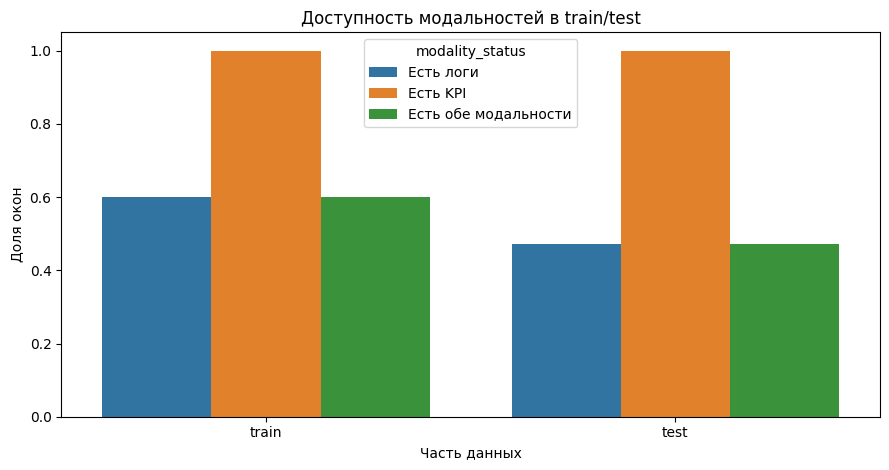

In [35]:
plot_df = (
    split_summary[
        ["split", "log_available_share", "kpi_available_share", "both_modalities_share"]
    ]
    .rename(
        columns={
            "log_available_share": "Есть логи",
            "kpi_available_share": "Есть KPI",
            "both_modalities_share": "Есть обе модальности",
        }
    )
    .melt(
        id_vars="split",
        var_name="modality_status",
        value_name="share",
    )
)

plot_df["split"] = pd.Categorical(
    plot_df["split"],
    categories=["train", "test"],
    ordered=True,
)

plt.figure(figsize=(9, 4.8))

sns.barplot(
    data=plot_df,
    x="split",
    y="share",
    hue="modality_status",
)

plt.title("Доступность модальностей в train/test")
plt.xlabel("Часть данных")
plt.ylabel("Доля окон")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

### Выводы по разделу

Итоговый набор окон из notebook `02` был загружен без пересборки данных и без восстановления split. Это важно для корректности эксперимента: notebook `03` принимает уже зафиксированные решения предыдущего этапа и не меняет условия оценки модели.

Проверки подтвердили, что в наборе присутствуют необходимые признаки для центральной fusion-модели: текст логов, агрегированные логовые признаки, KPI-поля, маски доступности модальностей и две целевые переменные. Отдельно контролировалось отсутствие повторяющихся окон, так как дубли могли бы исказить обучение и оценку.

График баланса целевых переменных нужен для интерпретации будущих метрик. Задача остаётся несбалансированной: положительные примеры встречаются реже отрицательных, особенно для `y_risk`. Поэтому в следующих разделах модель должна учитывать дисбаланс классов, а качество лучше оценивать не только через accuracy, но и через метрики, чувствительные к положительному классу.

График доступности модальностей показывает, что не каждое окно содержит одновременно логи и KPI. Поэтому выбранная missing-aware fusion-архитектура здесь оправдана: модель должна уметь работать не только с полным набором модальностей, но и с частичными наблюдениями.

## 3. Группы признаков и validation-разбиение

В этом разделе фиксируется, какие признаки будут переданы в центральную модель и как из обучающей части выделяется validation-набор. Train/test-разбиение уже пришло из notebook `02` и в текущем notebook не изменяется. Validation создаётся только внутри train-части и только для выбора параметров обучения.

KPI-признаки восстанавливаются напрямую из колонок итогового набора окон. Это делает notebook менее зависимым от дополнительных служебных файлов: фактическим источником признаков является сам contract из notebook `02`.

Отдельно проверяется, что в список модельных признаков не попали идентификаторы запусков, временные метки, целевые переменные и другие поля, которые могли бы привести к утечке информации.

### 3.1. Выделение групп признаков

Эта ячейка собирает группы входов для модели: логовые признаки macro- и micro-уровня, KPI-ряды, признаки доступности модальностей и целевые переменные. Подробные списки колонок не выводятся в notebook, но сохраняются в `feature_manifest`, чтобы дальнейшие этапы могли воспроизвести порядок признаков.

In [36]:
def extract_kpi_bases_from_columns(columns, stat_order=STAT_ORDER):
    suffixes = tuple("__" + stat for stat in stat_order)
    bases = []

    for col in columns:
        if not col.startswith("kpi_") or not col.endswith(suffixes):
            continue

        for stat in stat_order:
            suffix = "__" + stat

            if col.endswith(suffix):
                bases.append(col[: -len(suffix)])
                break

    return sorted(set(bases))


# KPI-ряды восстанавливаются только из фактических колонок contract.
selected_series = extract_kpi_bases_from_columns(df.columns)
series_order_source = "contract_column_names"

if not selected_series:
    raise ValueError("Не удалось восстановить KPI-ряды из колонок итогового набора окон")


missing_stat_columns = []
kpi_feature_cols = []

for base in selected_series:
    for stat in STAT_ORDER:
        col = f"{base}__{stat}"

        if col in df.columns:
            kpi_feature_cols.append(col)
        else:
            missing_stat_columns.append(col)


# Эти поля не должны попадать в predictive features.
leakage_cols = {
    "workload",
    "scenario",
    "run_id",
    "group_id",
    "failure_family",
    "scenario_type",
    "state",
    "anchor_policy",
    "window_ts",
    "window_end",
    "run_start",
    "run_end",
    "fail_start",
    "event_anchor",
    "minutes_before_fail",
    "target_available",
    "target_policy",
    "split",
    "split_group",
    "y_warning",
    "y_risk",
    "y_anomaly",
    "macro_window_sec",
    "micro_window_sec",
}


predictive_feature_names = set(
    LOG_MACRO_COLS
    + LOG_MICRO_COLS
    + MODEL_MASK_COLS
    + KPI_MICRO_COLS
    + kpi_feature_cols
    + ["log_text"]
)

leakage_intersection = sorted(
    (predictive_feature_names - {"log_text"}) & leakage_cols
)

if leakage_intersection:
    raise ValueError(
        "В список модельных признаков попали поля с риском утечки: "
        f"{leakage_intersection}"
    )


feature_group_summary = pd.DataFrame(
    [
        {"feature_group": "Log macro-признаки", "count": len(LOG_MACRO_COLS)},
        {"feature_group": "Log micro-признаки", "count": len(LOG_MICRO_COLS)},
        {"feature_group": "KPI-ряды", "count": len(selected_series)},
        {"feature_group": "KPI statistic-признаки", "count": len(kpi_feature_cols)},
        {"feature_group": "KPI context-признаки", "count": len(KPI_MICRO_COLS)},
        {"feature_group": "Маски для fusion", "count": len(MODEL_MASK_COLS)},
    ]
)


feature_manifest = {
    "contract_path": str(CONTRACT_PATH.relative_to(ROOT)),
    "series_order_source": series_order_source,
    "selected_series_count": int(len(selected_series)),
    "selected_series": selected_series,
    "stat_order": STAT_ORDER,
    "kpi_feature_cols_count": int(len(kpi_feature_cols)),
    "kpi_feature_cols": kpi_feature_cols,
    "missing_stat_columns_count": int(len(missing_stat_columns)),
    "missing_stat_columns_sample": missing_stat_columns[:20],
    "log_macro_cols": LOG_MACRO_COLS,
    "log_micro_cols": LOG_MICRO_COLS,
    "model_mask_cols": MODEL_MASK_COLS,
    "kpi_micro_cols": KPI_MICRO_COLS,
    "excluded_leakage_cols": sorted(leakage_cols),
    "leakage_intersection": leakage_intersection,
}


display(
    Markdown(
        f"""
**Группы признаков собраны.**

- log macro-признаков: **{len(LOG_MACRO_COLS)}**
- log micro-признаков: **{len(LOG_MICRO_COLS)}**
- KPI-рядов: **{len(selected_series)}**
- KPI statistic-признаков: **{len(kpi_feature_cols)}**
- отсутствующих KPI statistic-колонок: **{len(missing_stat_columns)}**
- источник порядка KPI-рядов: **{series_order_source}**
"""
    )
)


**Группы признаков собраны.**

- log macro-признаков: **6**
- log micro-признаков: **7**
- KPI-рядов: **432**
- KPI statistic-признаков: **2160**
- отсутствующих KPI statistic-колонок: **0**
- источник порядка KPI-рядов: **contract_column_names**


### 3.2. Размерность входных блоков модели

График ниже показывает, насколько различаются группы признаков по размерности. Он нужен не для диагностики ошибки, а для обоснования архитектуры: KPI-блок значительно шире логовых агрегатов, поэтому его нецелесообразно просто добавлять к остальным признакам как обычную плоскую таблицу.

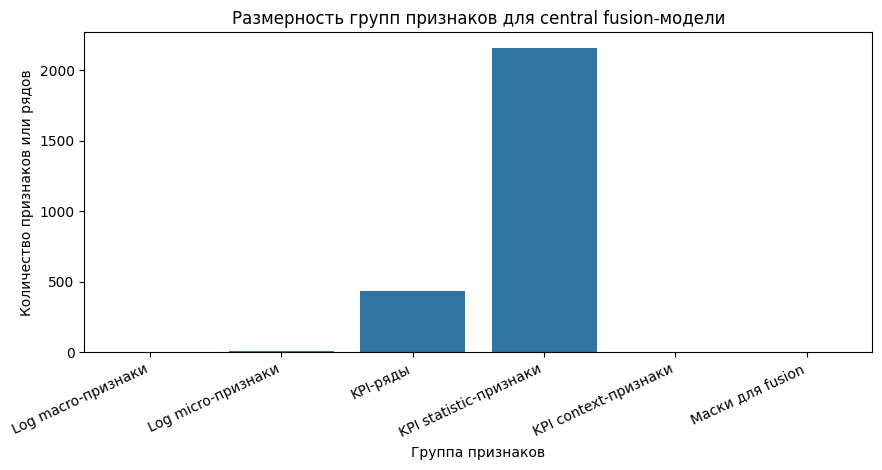

In [37]:
plot_df = feature_group_summary.copy()

plt.figure(figsize=(9, 4.8))

sns.barplot(
    data=plot_df,
    x="feature_group",
    y="count",
)

plt.title("Размерность групп признаков для central fusion-модели")
plt.xlabel("Группа признаков")
plt.ylabel("Количество признаков или рядов")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

### 3.3. Формирование validation-разбиения

Train/test-разбиение в текущем notebook не пересоздаётся: оно было зафиксировано в notebook `02`. Однако для обучения нейросетевой модели нужна отдельная validation-часть, по которой можно выбирать эпоху остановки и контролировать переобучение.

Validation выделяется только из train-части. Разделение выполняется по `run_id`, чтобы окна одного запуска не попадали одновременно в train и validation. Это уменьшает риск завышенной оценки качества из-за похожести соседних окон одного запуска.

In [38]:
primary_train_idx = df.index[df["split"] == "train"].to_numpy(dtype=np.int64)
test_idx = df.index[df["split"] == "test"].to_numpy(dtype=np.int64)

if len(primary_train_idx) == 0 or len(test_idx) == 0:
    raise ValueError("Train/test-разбиение должно содержать непустые train и test части")


def make_inner_val_split(frame, candidate_idx, group_col="run_id", val_size=0.20, seed=SEED):
    sub = frame.iloc[candidate_idx].reset_index(drop=True)
    groups = sub[group_col].astype(str).to_numpy()

    for offset in range(50):
        splitter = GroupShuffleSplit(
            n_splits=1,
            test_size=val_size,
            random_state=seed + offset,
        )

        inner_pos, val_pos = next(splitter.split(sub, groups=groups))

        inner_idx = candidate_idx[inner_pos]
        val_idx = candidate_idx[val_pos]

        warning_ok = (
            frame.iloc[inner_idx]["y_warning"].nunique() == 2
            and frame.iloc[val_idx]["y_warning"].nunique() == 2
        )
        risk_ok = (
            frame.iloc[inner_idx]["y_risk"].nunique() == 2
            and frame.iloc[val_idx]["y_risk"].nunique() == 2
        )

        if warning_ok and risk_ok:
            return inner_idx, val_idx, {
                "method": "GroupShuffleSplit_by_run_id",
                "seed": seed + offset,
                "val_size": val_size,
                "both_targets_have_two_classes": True,
            }

    raise ValueError(
        "Не удалось выделить validation-часть с двумя классами для обеих целевых переменных"
    )


train_idx, val_idx, inner_split_info = make_inner_val_split(df, primary_train_idx)


split_passport = {
    "primary_split_source": "contract_split_column",
    "inner_validation": inner_split_info,
    "train_rows": int(len(train_idx)),
    "val_rows": int(len(val_idx)),
    "test_rows": int(len(test_idx)),
    "train_runs": int(df.iloc[train_idx]["run_id"].nunique()),
    "val_runs": int(df.iloc[val_idx]["run_id"].nunique()),
    "test_runs": int(df.iloc[test_idx]["run_id"].nunique()),
    "train_workloads": sorted(df.iloc[train_idx]["workload"].unique().tolist()),
    "val_workloads": sorted(df.iloc[val_idx]["workload"].unique().tolist()),
    "test_workloads": sorted(df.iloc[test_idx]["workload"].unique().tolist()),
}

feature_manifest["split_passport"] = split_passport


model_split_df = pd.DataFrame(
    [
        {
            "split": "train",
            "rows": split_passport["train_rows"],
            "runs": split_passport["train_runs"],
        },
        {
            "split": "validation",
            "rows": split_passport["val_rows"],
            "runs": split_passport["val_runs"],
        },
        {
            "split": "test",
            "rows": split_passport["test_rows"],
            "runs": split_passport["test_runs"],
        },
    ]
)


display(
    Markdown(
        f"""
**Validation-разбиение сформировано.**

- train: **{split_passport["train_rows"]:,}** окон, **{split_passport["train_runs"]}** запусков
- validation: **{split_passport["val_rows"]:,}** окон, **{split_passport["val_runs"]}** запусков
- test: **{split_passport["test_rows"]:,}** окон, **{split_passport["test_runs"]}** запусков
- способ выделения validation: **{inner_split_info["method"]}**
"""
    )
)


**Validation-разбиение сформировано.**

- train: **5,949** окон, **261** запусков
- validation: **1,721** окон, **66** запусков
- test: **2,567** окон, **113** запусков
- способ выделения validation: **GroupShuffleSplit_by_run_id**


### 3.4. Размеры train, validation и test

Этот график показывает итоговое разбиение, которое будет использоваться в обучении модели. Важно, что test-часть остаётся исходной частью из notebook `02`, а validation выделяется только из train. Поэтому test не участвует ни в выборе эпохи обучения, ни в подборе порогов.

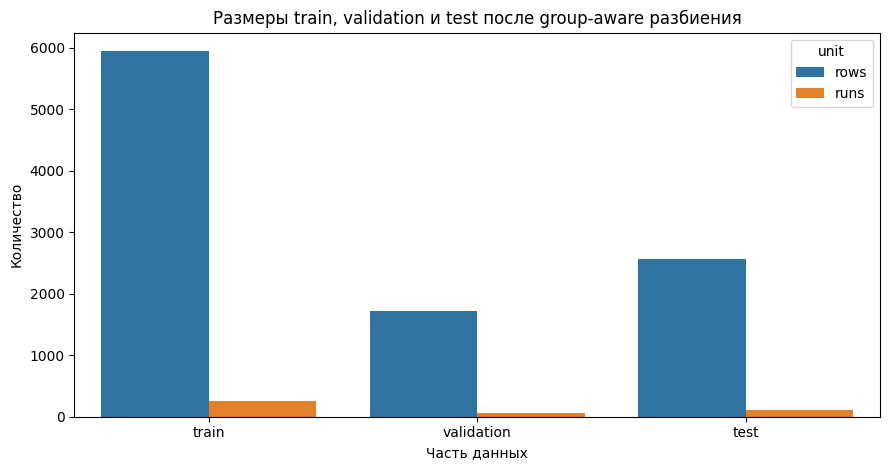

In [39]:
plot_df = model_split_df.melt(
    id_vars="split",
    value_vars=["rows", "runs"],
    var_name="unit",
    value_name="count",
)

plot_df["split"] = pd.Categorical(
    plot_df["split"],
    categories=["train", "validation", "test"],
    ordered=True,
)

plt.figure(figsize=(9, 4.8))

sns.barplot(
    data=plot_df,
    x="split",
    y="count",
    hue="unit",
)

plt.title("Размеры train, validation и test после group-aware разбиения")
plt.xlabel("Часть данных")
plt.ylabel("Количество")
plt.tight_layout()
plt.show()

### Выводы по разделу

В этом разделе были определены входные группы признаков для центральной fusion-модели. Логовая часть разделена на macro- и micro-признаки, KPI-часть восстановлена по фактическим колонкам итогового набора окон, а признаки доступности модальностей выделены отдельно для последующего fusion-блока. Такое разбиение соответствует структуре данных: логи описывают событийную активность, KPI отражают числовое состояние системы, а маски показывают, какие источники информации доступны в каждом окне.

График размерности признаковых групп показывает, что KPI-блок существенно крупнее логовых агрегатов. Из этого следует, что простое объединение всех признаков в одну плоскую таблицу было бы не самым удачным вариантом: модель могла бы переобучаться на высокоразмерные KPI-статистики и хуже использовать различие между модальностями. Поэтому дальнейшая архитектура должна обрабатывать KPI и логи раздельно, а объединять их уже на уровне скрытых представлений.

Validation-часть была выделена только из train-части и с учётом `run_id`. Это важно, потому что несколько окон одного запуска могут быть близки друг к другу по признакам и целевым значениям. Если такие окна одновременно попадут в обучение и validation, оценка на validation может оказаться слишком оптимистичной. Test-часть при этом остаётся неизменной и будет использоваться только для финальной проверки качества.

Таким образом, после этого раздела зафиксированы две вещи: какие признаки поступают в модель и каким образом будет контролироваться переобучение во время обучения. Ограничения исходной постановки сохраняются: целевые переменные остаются proxy-разметкой, а доступность модальностей сама по себе может быть связана с целевыми событиями. Поэтому в следующих разделах важно не только обучить модель, но и проверить, не опирается ли она слишком сильно на признаки покрытия данных.

## 4. Подготовка входов для central fusion-модели

В этом разделе группы признаков переводятся в формат, который можно передать в нейросетевую модель. Логовая часть представляется через текстовые embedding и числовые агрегаты micro/macro-окон, KPI-часть собирается в тензор «статистика × ряд», а признаки доступности модальностей сохраняются отдельной матрицей для fusion-блока.

Для полного обучения используется encoder `google/embeddinggemma-300m`. В локальном режиме `debug` он намеренно не загружается: вместо этого применяется быстрый hashing-вариант, который нужен только для проверки формы данных и прохождения вычислительного графа. В режиме `train` отсутствие HF-encoder считается ошибкой, потому что итоговый эксперимент должен выполняться на заявленной текстовой модели.

### 4.1. Функции подготовки признаков

Эта ячейка содержит только преобразования, которые нужны перед моделью: нормализацию логового текста, получение embedding, стандартизацию числовых признаков и сборку KPI-тензора. Все параметры масштабирования считаются только на train-части.

In [40]:
def stable_json_hash(payload, n_chars=16):
    text = json.dumps(json_sanitize(payload), ensure_ascii=False, sort_keys=True)
    return hashlib.sha1(text.encode("utf-8")).hexdigest()[:n_chars]


def file_sha1(path: Path, chunk_size=8 * 1024 * 1024):
    path = Path(path)
    hasher = hashlib.sha1()
    with path.open("rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            hasher.update(chunk)
    return hasher.hexdigest()


def l2_normalize_matrix(x, eps=1e-8):
    x = np.asarray(x, dtype=np.float32)
    norms = np.linalg.norm(x, axis=1, keepdims=True)
    return (x / np.clip(norms, eps, None)).astype(np.float32)


def normalize_log_text(text, max_chars=None, profile=None):
    max_chars = int(max_chars or TEXT_MAX_CHARS)
    profile = profile or TEXT_PROFILE
    value = str(text).strip()
    if not value:
        return "__NO_LOG__"

    lines = [line.strip() for line in value.splitlines() if line.strip()]
    if not lines:
        return "__NO_LOG__"

    pattern = re.compile(
        r"(error|warn|fail|failed|failure|exception|timeout|critical|fatal|oom|out of memory|killed|lost|denied|refused|unhealthy)",
        flags=re.IGNORECASE,
    )
    important_limit = {"short": 6, "balanced": 8, "full": 12}.get(profile, 8)
    tail_limit = {"short": 3, "balanced": 4, "full": 6}.get(profile, 4)
    head_limit = {"short": 1, "balanced": 2, "full": 2}.get(profile, 2)

    important = [line for line in lines if pattern.search(line)][:important_limit]
    head = lines[:head_limit]
    tail = lines[-tail_limit:]

    selected = []
    seen = set()
    for line in important + head + tail:
        compact = re.sub(r"\s+", " ", line).strip()
        if compact and compact not in seen:
            selected.append(compact)
            seen.add(compact)

    text_out = " ".join(selected if selected else tail)
    text_out = re.sub(r"\s+", " ", text_out).strip()
    return text_out[:max_chars] if text_out else "__NO_LOG__"


def deterministic_hashing_embeddings(texts, dim=None):
    dim = int(dim or EMBEDDING_TRUNCATE_DIM or HASHING_FALLBACK_DIM)
    arr = np.zeros((len(texts), dim), dtype=np.float32)
    for i, text in enumerate(texts):
        for token in str(text).lower().split():
            h = int(hashlib.sha1(token.encode("utf-8")).hexdigest(), 16)
            arr[i, h % dim] += 1.0 if ((h >> 8) & 1) else -1.0
    return l2_normalize_matrix(arr)


def find_hf_token():
    for env_name in ["HF_TOKEN", "HUGGINGFACE_HUB_TOKEN", "HUGGINGFACE_TOKEN"]:
        token = os.getenv(env_name)
        if isinstance(token, str) and token.strip():
            return token.strip(), f"env:{env_name}"
    try:
        from huggingface_hub import get_token
        token = get_token()
        if isinstance(token, str) and token.strip():
            return token.strip(), "huggingface_hub_cache"
    except Exception:
        pass
    return None, "missing"


def check_hf_encoder():
    result = {
        "run_mode": RUN_MODE,
        "model_name": HF_GOOGLE_EMBEDDER_MODEL,
        "token_found": False,
        "token_source": "missing",
        "local_cache": False,
        "local_snapshot_path": None,
        "model_revision": None,
        "remote_access": False,
        "can_use_hf": False,
        "message": "",
    }

    token, token_source = find_hf_token()
    result["token_found"] = token is not None
    result["token_source"] = token_source

    try:
        from huggingface_hub import HfApi, snapshot_download
        from sentence_transformers import SentenceTransformer  # noqa: F401
    except Exception as exc:
        result["message"] = f"HF-библиотеки недоступны: {str(exc)[:160]}"
        return result

    try:
        snapshot_path = snapshot_download(
            repo_id=HF_GOOGLE_EMBEDDER_MODEL,
            token=token,
            local_files_only=True,
            endpoint=HF_ENDPOINT,
        )
        result["local_cache"] = True
        result["local_snapshot_path"] = str(snapshot_path)
        result["model_revision"] = Path(snapshot_path).name
        result["can_use_hf"] = True
        result["message"] = "Локальная копия encoder найдена."
        return result
    except Exception:
        pass

    if RUN_MODE == "train" and ALLOW_HF_DOWNLOAD and token is not None:
        try:
            api = HfApi(endpoint=HF_ENDPOINT) if HF_ENDPOINT else HfApi()
            info = api.model_info(HF_GOOGLE_EMBEDDER_MODEL, token=token)
            result["remote_access"] = True
            result["model_revision"] = getattr(info, "sha", None)
            result["can_use_hf"] = True
            result["message"] = "Доступ к HF-модели подтверждён, загрузка возможна."
            return result
        except Exception as exc:
            result["message"] = f"Нет доступа к HF-модели: {str(exc)[:180]}"
            return result

    if RUN_MODE == "debug":
        result["message"] = "В debug-режиме HF encoder не используется; будет применён hashing-вариант."
    else:
        result["message"] = "HF encoder недоступен для train-режима."
    return result


def resolve_hf_snapshot(hf_check):
    if RUN_MODE == "debug":
        return None, "debug"
    if hf_check.get("local_snapshot_path"):
        path = Path(hf_check["local_snapshot_path"])
        return path, path.name

    from huggingface_hub import snapshot_download
    token, _ = find_hf_token()
    snapshot_path = Path(
        snapshot_download(
            repo_id=HF_GOOGLE_EMBEDDER_MODEL,
            token=token,
            local_files_only=not ALLOW_HF_DOWNLOAD,
            max_workers=2,
            endpoint=HF_ENDPOINT,
        )
    )
    return snapshot_path, snapshot_path.name


def load_text_encoder(snapshot_path):
    if RUN_MODE == "debug":
        return None, "deterministic_hashing_debug", EMBEDDING_TRUNCATE_DIM

    from sentence_transformers import SentenceTransformer
    device_name = "cuda" if torch.cuda.is_available() else "cpu"
    encoder = SentenceTransformer(str(snapshot_path), device=device_name)
    if hasattr(encoder, "get_embedding_dimension"):
        full_dim = int(encoder.get_embedding_dimension())
    else:
        full_dim = int(encoder.get_sentence_embedding_dimension())
    return encoder, HF_GOOGLE_EMBEDDER_MODEL, full_dim


def contract_fingerprint_for_embedding(frame, contract_path=CONTRACT_PATH):
    path = Path(contract_path)
    if path.exists():
        return file_sha1(path)
    fallback = {
        "rows": int(len(frame)),
        "columns": list(frame.columns),
        "run_ids": sorted(frame["run_id"].astype(str).unique().tolist()) if "run_id" in frame.columns else [],
    }
    return stable_json_hash(fallback, n_chars=40)


def _read_current_embedding_cache(cache_file, expected_dim, expected_cache_key):
    if not cache_file.exists():
        return {}, None
    payload = np.load(cache_file, allow_pickle=True)
    metadata = {}
    if "metadata" in payload:
        try:
            metadata = json.loads(str(payload["metadata"][0]))
        except Exception:
            metadata = {}
    if metadata.get("cache_key") != expected_cache_key:
        return {}, metadata

    cache = {}
    for h, e in zip(payload["hashes"], payload["embeddings"]):
        e = np.asarray(e, dtype=np.float32)
        if e.shape[0] == expected_dim:
            cache[str(h)] = e
    return cache, metadata


def _encode_missing_texts(encoder, texts, truncate_dim, full_embedding_dim):
    if not texts:
        return np.zeros((0, truncate_dim), dtype=np.float32)

    encode_kwargs = dict(
        batch_size=HF_EMBED_BATCH_SIZE,
        show_progress_bar=True,
        normalize_embeddings=True,
        convert_to_numpy=True,
    )
    if truncate_dim and truncate_dim < full_embedding_dim:
        encode_kwargs["truncate_dim"] = int(truncate_dim)

    try:
        encoded = encoder.encode(texts, **encode_kwargs).astype(np.float32)
    except TypeError:
        encode_kwargs.pop("truncate_dim", None)
        encoded = encoder.encode(texts, **encode_kwargs).astype(np.float32)
        encoded = encoded[:, :truncate_dim]

    if encoded.shape[1] > truncate_dim:
        encoded = encoded[:, :truncate_dim]
    return l2_normalize_matrix(encoded)


def embed_logs(texts, fit_idx, hf_check):
    total_start = time.perf_counter()
    timing = {}
    contract_fingerprint = contract_fingerprint_for_embedding(df)

    t0 = time.perf_counter()
    normalized = [
        normalize_log_text(text, max_chars=TEXT_MAX_CHARS, profile=TEXT_PROFILE)
        for text in pd.Series(texts).fillna("").astype(str)
    ]
    hashes = [hashlib.sha1(text.encode("utf-8")).hexdigest() for text in normalized]
    timing["normalization_sec"] = time.perf_counter() - t0

    if RUN_MODE == "debug":
        encoder_name = "deterministic_hashing_debug"
        model_revision = "debug"
        full_embedding_dim = int(EMBEDDING_TRUNCATE_DIM)
        embedding_dim = int(EMBEDDING_TRUNCATE_DIM)
        cache_file = None
        raw_embeddings = deterministic_hashing_embeddings(normalized, dim=embedding_dim)
        encoded_this_run = len(set(normalized))
        cache_hit_rate = 0.0
        cache_hits = 0
        cache_misses = encoded_this_run
        cache_key = None
        cache_loaded = False
        encoder_loaded = False
    else:
        snapshot_path, model_revision = resolve_hf_snapshot(hf_check)
        encoder_name = HF_GOOGLE_EMBEDDER_MODEL
        embedding_dim = int(EMBEDDING_TRUNCATE_DIM)
        cache_scope = {
            "cache_schema": "current-log-embeddings-v2",
            "contract_fingerprint": contract_fingerprint,
            "encoder_name": encoder_name,
            "model_revision": model_revision,
            "normalizer_version": TEXT_NORMALIZER_VERSION,
            "text_profile": TEXT_PROFILE,
            "max_chars": TEXT_MAX_CHARS,
            "truncate_dim": embedding_dim,
        }
        cache_key = stable_json_hash(cache_scope, n_chars=20)
        safe_encoder_name = encoder_name.replace("/", "__")
        cache_file_path = CACHE_DIR / f"log_embeddings_current_{safe_encoder_name}_{cache_key}.npz"

        t0 = time.perf_counter()
        cache, cache_metadata = _read_current_embedding_cache(
            cache_file_path,
            expected_dim=embedding_dim,
            expected_cache_key=cache_key,
        )
        timing["cache_load_sec"] = time.perf_counter() - t0

        unique_pairs = []
        seen = set()
        for h, text in zip(hashes, normalized):
            if h not in seen:
                unique_pairs.append((h, text))
                seen.add(h)
        missing = [(h, text) for h, text in unique_pairs if h not in cache]
        cache_hits = len(unique_pairs) - len(missing)
        cache_misses = len(missing)
        cache_hit_rate = cache_hits / max(len(unique_pairs), 1)
        cache_loaded = cache_file_path.exists() and cache_hits > 0
        encoder_loaded = False
        full_embedding_dim = None

        if missing:
            t0 = time.perf_counter()
            encoder, encoder_name, full_embedding_dim = load_text_encoder(snapshot_path)
            encoder_loaded = encoder is not None
            timing["encoder_load_sec"] = time.perf_counter() - t0
            t0 = time.perf_counter()
            encoded = _encode_missing_texts(
                encoder,
                [text for _, text in missing],
                truncate_dim=embedding_dim,
                full_embedding_dim=full_embedding_dim,
            )
            timing["encoder_encode_sec"] = time.perf_counter() - t0
            for (h, _), e in zip(missing, encoded):
                cache[h] = e
        else:
            timing["encoder_load_sec"] = 0.0
            timing["encoder_encode_sec"] = 0.0
            full_embedding_dim = int(cache_metadata.get("full_embedding_dim", embedding_dim)) if cache_metadata else embedding_dim

        t0 = time.perf_counter()
        ordered_hashes = list(cache.keys())
        cache_metadata = dict(cache_scope)
        cache_metadata.update(
            {
                "cache_key": cache_key,
                "created_at_unix": time.time(),
                "full_embedding_dim": int(full_embedding_dim),
                "embedding_dim": int(embedding_dim),
                "unique_texts": int(len(unique_pairs)),
            }
        )
        np.savez_compressed(
            cache_file_path,
            hashes=np.array(ordered_hashes, dtype=object),
            embeddings=np.vstack([cache[h] for h in ordered_hashes]).astype(np.float32),
            metadata=np.array([json.dumps(json_sanitize(cache_metadata), ensure_ascii=False)], dtype=object),
        )
        timing["cache_save_sec"] = time.perf_counter() - t0
        raw_embeddings = np.vstack([cache[h] for h in hashes]).astype(np.float32)
        raw_embeddings = l2_normalize_matrix(raw_embeddings)
        encoded_this_run = len(missing)
        cache_file = str(cache_file_path.relative_to(ROOT))

    t0 = time.perf_counter()
    scaler = StandardScaler()
    scaler.fit(raw_embeddings[fit_idx])
    embeddings = scaler.transform(raw_embeddings).astype(np.float32)
    timing["scaling_sec"] = time.perf_counter() - t0
    timing["total_sec"] = time.perf_counter() - total_start

    text_lengths = np.array([len(text) for text in normalized], dtype=np.int64)
    word_counts = np.array([len(text.split()) for text in normalized], dtype=np.int64)
    manifest = {
        "encoder_name": encoder_name,
        "encoder_loaded": bool(encoder_loaded),
        "model_revision": model_revision,
        "normalizer_version": TEXT_NORMALIZER_VERSION,
        "text_profile": TEXT_PROFILE,
        "max_chars": int(TEXT_MAX_CHARS),
        "truncate_dim": int(EMBEDDING_TRUNCATE_DIM),
        "full_embedding_dim": int(full_embedding_dim),
        "embedding_dim": int(embeddings.shape[1]),
        "embedding_shape": list(embeddings.shape),
        "contract_fingerprint": contract_fingerprint,
        "cache_key": cache_key,
        "cache_file": cache_file,
        "cache_loaded": bool(cache_loaded),
        "cache_hits": int(cache_hits),
        "cache_misses": int(cache_misses),
        "cache_hit_rate": float(cache_hit_rate),
        "unique_normalized_texts": int(pd.Series(normalized).nunique()),
        "encoded_texts_this_run": int(encoded_this_run),
        "empty_log_text_share": float(np.mean([text == "__NO_LOG__" for text in normalized])),
        "truncated_text_share": float(np.mean(text_lengths >= TEXT_MAX_CHARS)),
        "char_len_p50": int(np.percentile(text_lengths, 50)) if len(text_lengths) else 0,
        "char_len_p95": int(np.percentile(text_lengths, 95)) if len(text_lengths) else 0,
        "word_count_p50": int(np.percentile(word_counts, 50)) if len(word_counts) else 0,
        "word_count_p95": int(np.percentile(word_counts, 95)) if len(word_counts) else 0,
        "scaler_fit_rows": int(len(fit_idx)),
        "timing_sec": {key: float(value) for key, value in timing.items()},
    }
    artifacts = {
        "scaler": scaler,
        "cache_file": cache_file,
        "normalizer_version": TEXT_NORMALIZER_VERSION,
        "text_profile": TEXT_PROFILE,
        "max_chars": TEXT_MAX_CHARS,
        "truncate_dim": EMBEDDING_TRUNCATE_DIM,
    }
    return embeddings, artifacts, manifest


def fit_scaled_numeric_matrix(frame, cols, fit_idx, transform_fn=None):
    raw = frame[cols].apply(pd.to_numeric, errors="coerce").astype(np.float32)
    if transform_fn is not None:
        raw = transform_fn(raw.copy())
    x = raw.to_numpy(dtype=np.float32, copy=True)
    imputer = SimpleImputer(strategy="median")
    imputer.fit(x[fit_idx])
    x = imputer.transform(x).astype(np.float32)
    scaler = StandardScaler()
    scaler.fit(x[fit_idx])
    return scaler.transform(x).astype(np.float32), {"imputer": imputer, "scaler": scaler}


def transform_kpi_micro(raw):
    raw["kpi_recency_sec"] = np.log1p(
        np.clip(pd.to_numeric(raw["kpi_recency_sec"], errors="coerce"), 0, None)
    )
    return raw


def build_mask_matrix(frame):
    x = (
        frame[MODEL_MASK_COLS]
        .apply(pd.to_numeric, errors="coerce")
        .fillna(0.0)
        .to_numpy(dtype=np.float32)
    )
    return np.clip(x, 0.0, 1.0)


def build_kpi_tensor(frame, selected_series, fit_idx):
    n_rows = len(frame)
    n_series = len(selected_series)
    n_stats = len(STAT_ORDER)
    raw = np.full((n_rows, n_stats, n_series), np.nan, dtype=np.float32)
    for stat_i, stat in enumerate(STAT_ORDER):
        cols = [f"{base}__{stat}" for base in selected_series]
        present = [(i, col) for i, col in enumerate(cols) if col in frame.columns]
        if present:
            pos, present_cols = zip(*present)
            raw[:, stat_i, list(pos)] = (
                frame[list(present_cols)]
                .apply(pd.to_numeric, errors="coerce")
                .to_numpy(dtype=np.float32, copy=True)
            )

    availability = np.isfinite(raw).any(axis=1).astype(np.float32)
    train_raw = raw[fit_idx]
    with np.errstate(invalid="ignore", divide="ignore"):
        means = np.nanmean(train_raw, axis=0).astype(np.float32)
        stds = np.nanstd(train_raw, axis=0).astype(np.float32)
    means = np.where(np.isfinite(means), means, 0.0)
    stds = np.where(np.isfinite(stds) & (stds > 1e-6), stds, 1.0)
    normalized = (raw - means[None, :, :]) / stds[None, :, :]
    normalized = np.where(np.isfinite(normalized), normalized, 0.0).astype(np.float32)
    tensor = np.concatenate([normalized, availability[:, None, :]], axis=1).astype(np.float32)
    return tensor, availability, {"means": means, "stds": stds}


### 4.2. Проверка HF и выбор рабочего режима

Эта ячейка заранее проверяет, доступен ли HF encoder. В режиме `debug` дополнительно создаётся компактная подвыборка, чтобы быстро проверить preprocessing и последующий forward pass модели. В режиме `train` используется полный набор окон.

In [41]:
HF_CHECK = check_hf_encoder()

display(
    Markdown(
        f"""
**Проверка текстового encoder**

- режим запуска: **{RUN_MODE}**
- модель: **{HF_CHECK["model_name"]}**
- token найден: **{HF_CHECK["token_found"]}**
- локальный cache: **{HF_CHECK["local_cache"]}**
- доступ к модели: **{HF_CHECK["can_use_hf"]}**

{HF_CHECK["message"]}
"""
    )
)

if RUN_MODE == "train" and not HF_CHECK["can_use_hf"]:
    raise RuntimeError("В режиме train нельзя продолжать без доступного HF encoder.")


if "df_full" not in globals():
    df_full = df.copy()
    train_idx_full = train_idx.copy()
    val_idx_full = val_idx.copy()
    test_idx_full = test_idx.copy()


def sample_debug_indices(source_idx, max_rows=400):
    rng = np.random.default_rng(SEED)
    source_idx = np.asarray(source_idx, dtype=np.int64)

    keep = []

    for target in TARGET_COLS:
        for value in [0, 1]:
            candidates = df_full.iloc[source_idx].index[
                df_full.iloc[source_idx][target].astype(int).eq(value)
            ].to_numpy(dtype=np.int64)

            if len(candidates):
                take = min(25, len(candidates))
                keep.extend(rng.choice(candidates, size=take, replace=False).tolist())

    keep = np.array(sorted(set(keep)), dtype=np.int64)
    rest = np.setdiff1d(source_idx, keep)

    need = max(0, min(max_rows, len(source_idx)) - len(keep))
    if need and len(rest):
        keep = np.concatenate(
            [keep, rng.choice(rest, size=min(need, len(rest)), replace=False)]
        )

    return np.array(sorted(set(keep)), dtype=np.int64)


if RUN_MODE == "debug":
    debug_idx = np.sort(
        np.concatenate(
            [
                sample_debug_indices(train_idx_full, max_rows=400),
                sample_debug_indices(val_idx_full, max_rows=250),
                sample_debug_indices(test_idx_full, max_rows=250),
            ]
        )
    )

    old_to_new = {old: new for new, old in enumerate(debug_idx)}

    df = df_full.loc[debug_idx].reset_index(drop=True)
    train_idx = np.array([old_to_new[i] for i in train_idx_full if i in old_to_new], dtype=np.int64)
    val_idx = np.array([old_to_new[i] for i in val_idx_full if i in old_to_new], dtype=np.int64)
    test_idx = np.array([old_to_new[i] for i in test_idx_full if i in old_to_new], dtype=np.int64)

else:
    df = df_full.copy()
    train_idx = train_idx_full.copy()
    val_idx = val_idx_full.copy()
    test_idx = test_idx_full.copy()


**Проверка текстового encoder**

- режим запуска: **train**
- модель: **google/embeddinggemma-300m**
- token найден: **True**
- локальный cache: **True**
- доступ к модели: **True**

Локальная копия encoder найдена.


### 4.3a. Text embedding cache

На этом шаге log-тексты нормализуются до компактного “сигнального” представления и переводятся в embedding-и. Кэш теперь привязан к fingerprint входного контракта, версии normalizer, профилю длины текста, revision encoder и `truncate_dim`, поэтому устаревший cache не маскирует пересчёт после изменения данных.

In [42]:
log_embedding, text_artifacts, text_manifest = embed_logs(
    df["log_text"],
    train_idx,
    HF_CHECK,
)

embedding_benchmark_df = pd.DataFrame(
    [
        {"Показатель": "Fingerprint contract", "Значение": text_manifest["contract_fingerprint"][:16]},
        {"Показатель": "Профиль текста", "Значение": text_manifest["text_profile"]},
        {"Показатель": "Максимум символов", "Значение": text_manifest["max_chars"]},
        {"Показатель": "truncate_dim", "Значение": text_manifest["truncate_dim"]},
        {"Показатель": "Уникальных normalized текстов", "Значение": text_manifest["unique_normalized_texts"]},
        {"Показатель": "Cache hits", "Значение": text_manifest["cache_hits"]},
        {"Показатель": "Cache misses", "Значение": text_manifest["cache_misses"]},
        {"Показатель": "Cache hit rate", "Значение": round(text_manifest["cache_hit_rate"], 4)},
        {"Показатель": "Encoded this run", "Значение": text_manifest["encoded_texts_this_run"]},
        {"Показатель": "Embedding total sec", "Значение": round(text_manifest["timing_sec"]["total_sec"], 3)},
    ]
)

display(embedding_benchmark_df)

display(
    Markdown(
        f"""
**Text embedding cache подготовлен.**

- encoder: **{text_manifest["encoder_name"]}**
- revision: `{text_manifest["model_revision"]}`
- cache file: `{text_manifest["cache_file"]}`
- cache hit rate: **{text_manifest["cache_hit_rate"]:.3f}**
- encoded this run: **{text_manifest["encoded_texts_this_run"]:,}**
- total time: **{text_manifest["timing_sec"]["total_sec"]:.2f} сек**
"""
    )
)


,Показатель,Значение
0,Fingerprint contract,7575b3722c565ca2
1,Профиль текста,balanced
2,Максимум символов,768
3,truncate_dim,256
4,Уникальных normalized текстов,3872
5,Cache hits,3872
6,Cache misses,0
7,Cache hit rate,1.0
8,Encoded this run,0
9,Embedding total sec,2.03



**Text embedding cache подготовлен.**

- encoder: **google/embeddinggemma-300m**
- revision: `57c266a740f537b4dc058e1b0cda161fd15afa75`
- cache file: `outputs\raw_central_model\cache\log_embeddings_current_google__embeddinggemma-300m_9d6f795d4ab42d4489e3.npz`
- cache hit rate: **1.000**
- encoded this run: **0**
- total time: **2.03 сек**


### 4.3b. Сборка входных массивов модели

После отдельного embedding-cache этапа все числовые блоки собираются в `arrays`. Масштабирование по-прежнему обучается только на train-части, а KPI сохраняет форму `статистика × ряд` для central fusion ветви.

In [43]:
array_stage_start = time.perf_counter()
array_timing = {}

t0 = time.perf_counter()
log_macro, macro_artifacts = fit_scaled_numeric_matrix(df, LOG_MACRO_COLS, train_idx)
array_timing["log_macro_sec"] = time.perf_counter() - t0

t0 = time.perf_counter()
log_micro, micro_artifacts = fit_scaled_numeric_matrix(df, LOG_MICRO_COLS, train_idx)
array_timing["log_micro_sec"] = time.perf_counter() - t0

t0 = time.perf_counter()
kpi_micro, kpi_micro_artifacts = fit_scaled_numeric_matrix(
    df,
    KPI_MICRO_COLS,
    train_idx,
    transform_fn=transform_kpi_micro,
)
array_timing["kpi_micro_sec"] = time.perf_counter() - t0

t0 = time.perf_counter()
mask_matrix = build_mask_matrix(df)
array_timing["mask_sec"] = time.perf_counter() - t0

t0 = time.perf_counter()
kpi_tensor, kpi_availability_channel, kpi_norm_stats = build_kpi_tensor(df, selected_series, train_idx)
array_timing["kpi_tensor_sec"] = time.perf_counter() - t0
array_timing["total_sec"] = time.perf_counter() - array_stage_start

arrays = {
    "log_embedding": log_embedding.astype(np.float32),
    "log_macro": log_macro.astype(np.float32),
    "log_micro": log_micro.astype(np.float32),
    "kpi_tensor": kpi_tensor.astype(np.float32),
    "kpi_micro": kpi_micro.astype(np.float32),
    "masks": mask_matrix.astype(np.float32),
    "y_warning": df["y_warning"].to_numpy(dtype=np.float32),
    "y_risk": df["y_risk"].to_numpy(dtype=np.float32),
}

feature_manifest["tensor_shapes"] = {
    name: list(value.shape)
    for name, value in arrays.items()
    if name not in TARGET_COLS
}
feature_manifest["text_encoder"] = text_manifest
feature_manifest["preprocessing_timing_sec"] = {
    "embedding": text_manifest["timing_sec"],
    "arrays": {key: float(value) for key, value in array_timing.items()},
}

preprocessing_artifacts = {
    "text": text_artifacts,
    "log_macro": macro_artifacts,
    "log_micro": micro_artifacts,
    "kpi_micro": kpi_micro_artifacts,
    "kpi_tensor_stats": kpi_norm_stats,
}

preprocessing_manifest = {
    "run_mode": RUN_MODE,
    "contract_fingerprint": text_manifest["contract_fingerprint"],
    "text_embedding": text_manifest,
    "tensor_shapes": feature_manifest["tensor_shapes"],
    "preprocessing_timing_sec": feature_manifest["preprocessing_timing_sec"],
    "train_rows": int(len(train_idx)),
    "validation_rows": int(len(val_idx)),
    "test_rows": int(len(test_idx)),
}

display(
    Markdown(
        f"""
**Входы модели подготовлены.**

- строк в текущем режиме: **{len(df):,}**
- train / validation / test: **{len(train_idx):,} / {len(val_idx):,} / {len(test_idx):,}**
- encoder логов: **{text_manifest["encoder_name"]}**
- размерность embedding после truncation: **{text_manifest["embedding_dim"]}**
- KPI tensor: **{arrays["kpi_tensor"].shape}**
- доля окон без логового текста: **{text_manifest["empty_log_text_share"]:.3f}**
- сборка numeric/KPI arrays: **{array_timing["total_sec"]:.2f} сек**
"""
    )
)

_ = gc.collect()



**Входы модели подготовлены.**

- строк в текущем режиме: **10,237**
- train / validation / test: **5,949 / 1,721 / 2,567**
- encoder логов: **google/embeddinggemma-300m**
- размерность embedding после truncation: **256**
- KPI tensor: **(10237, 6, 432)**
- доля окон без логового текста: **0.432**
- сборка numeric/KPI arrays: **0.57 сек**


### 4.4. Размерность входных блоков

График показывает, какие по масштабу входы получает центральная модель. Текстовые embedding и KPI-ряды являются наиболее крупными блоками, тогда как логовые агрегаты и маски остаются компактными признаками контекста.

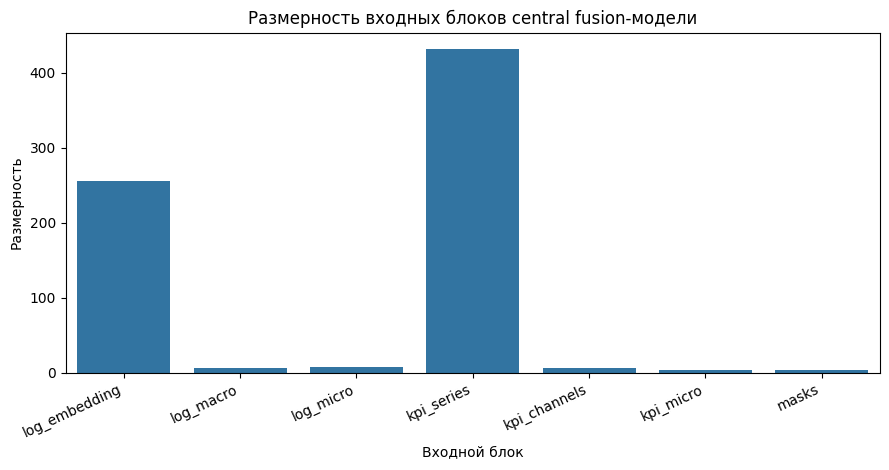

In [44]:
plot_df = pd.DataFrame(
    [
        {"input_block": "log_embedding", "dimension": arrays["log_embedding"].shape[1]},
        {"input_block": "log_macro", "dimension": arrays["log_macro"].shape[1]},
        {"input_block": "log_micro", "dimension": arrays["log_micro"].shape[1]},
        {"input_block": "kpi_series", "dimension": arrays["kpi_tensor"].shape[2]},
        {"input_block": "kpi_channels", "dimension": arrays["kpi_tensor"].shape[1]},
        {"input_block": "kpi_micro", "dimension": arrays["kpi_micro"].shape[1]},
        {"input_block": "masks", "dimension": arrays["masks"].shape[1]},
    ]
)

plt.figure(figsize=(9, 4.8))

sns.barplot(
    data=plot_df,
    x="input_block",
    y="dimension",
)

plt.title("Размерность входных блоков central fusion-модели")
plt.xlabel("Входной блок")
plt.ylabel("Размерность")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

### Выводы по разделу

В результате preprocessing все источники данных были приведены к тем формам, которые требуются central fusion-модели. Логовая часть представлена embedding-векторами текста, macro-признаками и micro-признаками. KPI-часть сохранена как тензор с отдельными каналами статистик и доступности значений. Маски модальностей выделены отдельно, поскольку они участвуют в дальнейшем механизме объединения логовой и KPI-ветвей.

График размерности входов показывает, что модель получает неоднородные по масштабу блоки. Текстовое представление и KPI-ряды дают наиболее крупные входы, а логовые агрегаты и маски играют роль компактного контекста. Это подтверждает необходимость раздельной обработки модальностей перед fusion-блоком.

В режиме `debug` preprocessing работает на компактной подвыборке и использует быстрый hashing-вариант вместо HF encoder. Такой запуск проверяет форму входов и позволяет перейти к проверке вычислительного графа без ожидания загрузки большой модели. В режиме `train` используется полный набор данных и заявленный HF encoder; если он недоступен, выполнение останавливается до начала обучения.

## 5. Карточка архитектуры central fusion-модели

В этом разделе задаётся вычислительный граф central fusion-модели. На вход модель получает не исходные сырые данные, а уже подготовленные массивы из preprocessing: `log_embedding`, `log_macro`, `log_micro`, `kpi_tensor`, `kpi_micro` и `masks`.

Важно разделить два этапа. HF encoder `google/embeddinggemma-300m` используется до модели, на этапе preprocessing, и превращает `log_text` в `log_embedding`. Внутри PyTorch-модели этот encoder не обучается. Обучаемая часть начинается с обработки уже готовых embedding-векторов и числовых признаков.

Модель построена как late fusion архитектура: сначала отдельно формируются логовое представление `h_log` и KPI-представление `h_kpi`, затем они объединяются через missing-aware gate. Такой вариант соответствует структуре данных, потому что часть окон содержит обе модальности, а часть — только одну из них.

### 5.1. Состав central fusion модели

| Компонент | Вход | Выход | Роль в модели |
|---|---|---|---|
| Log embedding projection | `log_embedding` | `h_text` | Обрабатывает компактное dense-представление логов после offline EmbeddingGemma-cache. |
| Log macro/micro branches | `log_macro`, `log_micro` | `h_macro`, `h_micro` | Кодируют широкий контекст и краткосрочную интенсивность логов. |
| Log fusion | `[h_text, h_macro, h_micro]` | `h_log` | Формирует лёгкое представление логовой модальности. |
| Shared KPI series encoder | `kpi_tensor[:, :, series]` | `series_h` | Один общий encoder для всех KPI-рядов без зависимости от физического порядка. |
| KPI attention pooling | `series_h` + availability | `h_kpi_series` | Выбирает наиболее информативные KPI-ряды и сохраняет attention weights для интерпретации. |
| KPI context branch | `kpi_micro` | `h_kpi_context` | Добавляет покрытие, свежесть и доступность KPI. |
| Missing-aware fusion attention | `h_log`, `h_kpi`, masks | `g` | Определяет вклад логовой ветви с жёстким fallback при отсутствии модальности. |
| Dual heads | `h_fused` | `warning_logit`, `risk_logit` | Предсказывает warning и risk, при этом training monitor отдельно учитывает recall по risk. |

В inference encoder не запускается внутри модели: runtime получает уже готовые embedding-и, числовые log/KPI признаки и masks. Это оставляет итоговую модель лёгкой для CPU-системы, а тяжёлый языковой encoder переносит в воспроизводимый offline-cache этап.

**Схема central fusion.**

`log_text -> offline EmbeddingGemma cache -> compact embedding`  
`log_embedding + log_macro + log_micro -> h_log`  
`kpi_tensor -> shared series encoder -> attention pooling -> h_kpi`  
`[h_log, h_kpi, masks] -> missing-aware fusion -> warning/risk heads`

**Локальный вывод.** Архитектура остаётся lightweight: в обучаемой части нет 300M encoder, а KPI attention добавляет интерпретируемость без перехода к тяжёлому transformer по всем рядам.

### 5.2. Реализация архитектуры

Эта ячейка определяет `Dataset`, модельные блоки, функцию потерь и вспомогательные функции. Обучение здесь ещё не выполняется. После объявления классов модель будет отдельно проверена на одном batch: это нужно, чтобы убедиться в совместимости входных tensors, размерностей выходов и функции потерь.

In [45]:
class CentralFusionDataset(Dataset):
    def __init__(self, arrays, indices):
        self.arrays = arrays
        self.indices = np.asarray(indices, dtype=np.int64)
        required_keys = [
            "log_embedding", "log_macro", "log_micro", "kpi_tensor",
            "kpi_micro", "masks", "y_warning", "y_risk",
        ]
        missing = [key for key in required_keys if key not in arrays]
        if missing:
            raise ValueError(f"В arrays отсутствуют обязательные входы: {missing}")

    def __len__(self):
        return int(len(self.indices))

    def __getitem__(self, item):
        idx = self.indices[item]
        return {
            "log_embedding": torch.from_numpy(self.arrays["log_embedding"][idx]),
            "log_macro": torch.from_numpy(self.arrays["log_macro"][idx]),
            "log_micro": torch.from_numpy(self.arrays["log_micro"][idx]),
            "kpi_tensor": torch.from_numpy(self.arrays["kpi_tensor"][idx]),
            "kpi_micro": torch.from_numpy(self.arrays["kpi_micro"][idx]),
            "masks": torch.from_numpy(self.arrays["masks"][idx]),
            "y_warning": torch.tensor(self.arrays["y_warning"][idx], dtype=torch.float32),
            "y_risk": torch.tensor(self.arrays["y_risk"][idx], dtype=torch.float32),
            "row_index": torch.tensor(idx, dtype=torch.long),
        }


def move_batch_to_device(batch, device):
    return {key: value.to(device) if torch.is_tensor(value) else value for key, value in batch.items()}


class DenseBlock(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, dropout=0.15, inner_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, inner_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(inner_dim, hidden_dim),
            nn.ReLU(),
        )

    def forward(self, x):
        return self.net(x)


class KPISeriesMeanMaxBranch(nn.Module):
    def __init__(self, channels, micro_dim, hidden_dim=64):
        super().__init__()
        self.series_encoder = nn.Sequential(
            nn.Linear(channels, 64),
            nn.ReLU(),
            nn.Dropout(0.10),
            nn.Linear(64, hidden_dim),
            nn.ReLU(),
        )
        self.micro_proj = DenseBlock(micro_dim, hidden_dim=32, dropout=0.10, inner_dim=64)
        self.out_proj = nn.Sequential(nn.Linear(hidden_dim * 2 + 32, hidden_dim), nn.ReLU())

    def forward(self, kpi_tensor, kpi_micro):
        x = kpi_tensor.transpose(1, 2)
        availability = kpi_tensor[:, -1, :] > 0.5
        availability_f = availability.float().unsqueeze(-1)
        series_h = self.series_encoder(x)
        denom = availability_f.sum(dim=1).clamp_min(1.0)
        pooled_mean = (series_h * availability_f).sum(dim=1) / denom
        masked_for_max = series_h.masked_fill(~availability.unsqueeze(-1), -1e9)
        pooled_max = masked_for_max.max(dim=1).values
        has_any_series = availability.any(dim=1, keepdim=True)
        pooled_max = torch.where(has_any_series, pooled_max, torch.zeros_like(pooled_max))
        h_micro = self.micro_proj(kpi_micro)
        attention = availability_f.squeeze(-1) / availability_f.squeeze(-1).sum(dim=1, keepdim=True).clamp_min(1.0)
        return self.out_proj(torch.cat([pooled_mean, pooled_max, h_micro], dim=1)), attention


class KPIAttentionPoolingBranch(nn.Module):
    """Permutation-aware KPI branch: общий series encoder + masked attention pooling."""

    def __init__(self, channels, micro_dim, hidden_dim=64):
        super().__init__()
        self.series_encoder = nn.Sequential(
            nn.Linear(channels, 64),
            nn.ReLU(),
            nn.Dropout(0.10),
            nn.Linear(64, hidden_dim),
            nn.ReLU(),
        )
        self.attention_score = nn.Sequential(nn.Linear(hidden_dim + 1, 32), nn.Tanh(), nn.Linear(32, 1))
        self.micro_proj = DenseBlock(micro_dim, hidden_dim=32, dropout=0.10, inner_dim=64)
        self.out_proj = nn.Sequential(nn.Linear(hidden_dim * 2 + 32, hidden_dim), nn.ReLU())

    def forward(self, kpi_tensor, kpi_micro):
        x = kpi_tensor.transpose(1, 2)
        availability = kpi_tensor[:, -1, :] > 0.5
        availability_f = availability.float().unsqueeze(-1)
        series_h = self.series_encoder(x)
        attention_input = torch.cat([series_h, availability_f], dim=-1)
        logits = self.attention_score(attention_input).squeeze(-1)
        logits = logits.masked_fill(~availability, -1e9)
        has_any_series = availability.any(dim=1, keepdim=True)
        attention = torch.softmax(logits, dim=1)
        attention = torch.where(has_any_series, attention, torch.zeros_like(attention))
        context = (series_h * attention.unsqueeze(-1)).sum(dim=1)
        denom = availability_f.sum(dim=1).clamp_min(1.0)
        pooled_mean = (series_h * availability_f).sum(dim=1) / denom
        h_micro = self.micro_proj(kpi_micro)
        return self.out_proj(torch.cat([context, pooled_mean, h_micro], dim=1)), attention


class CentralFusionMultiRate(nn.Module):
    def __init__(self, config):
        super().__init__()
        hidden = int(config["hidden_dim"])
        self.modality_dropout = float(np.clip(config.get("modality_dropout", 0.0), 0.0, 0.95))
        self.use_aux_heads = bool(config.get("use_aux_heads", True))
        self.kpi_pooling = config.get("kpi_pooling", "attention")
        self.fusion_mode = config.get("fusion_mode", "attention")

        self.text_branch = DenseBlock(config["log_embedding_dim"], hidden_dim=hidden, dropout=0.15)
        self.log_macro_branch = DenseBlock(config["log_macro_dim"], hidden_dim=hidden, dropout=0.10, inner_dim=64)
        self.log_micro_branch = DenseBlock(config["log_micro_dim"], hidden_dim=hidden, dropout=0.10, inner_dim=64)
        self.log_fuser = nn.Sequential(nn.Linear(hidden * 3, hidden), nn.ReLU())

        branch_cls = KPIAttentionPoolingBranch if self.kpi_pooling == "attention" else KPISeriesMeanMaxBranch
        self.kpi_branch = branch_cls(
            channels=config["kpi_channels"],
            micro_dim=config["kpi_micro_dim"],
            hidden_dim=hidden,
        )
        self.gate = nn.Linear(hidden * 2 + 4, 1)
        self.fusion_attention = nn.Sequential(nn.Linear(hidden * 2 + 4, hidden), nn.ReLU(), nn.Linear(hidden, 2))
        self.warning_head = nn.Sequential(nn.Linear(hidden, 32), nn.ReLU(), nn.Linear(32, 1))
        self.risk_head = nn.Sequential(nn.Linear(hidden, 32), nn.ReLU(), nn.Linear(32, 1))

        if self.use_aux_heads:
            self.log_only_warning_head = nn.Sequential(nn.Linear(hidden, 16), nn.ReLU(), nn.Linear(16, 1))
            self.kpi_only_warning_head = nn.Sequential(nn.Linear(hidden, 16), nn.ReLU(), nn.Linear(16, 1))
            self.fused_aux_warning_head = nn.Sequential(nn.Linear(hidden, 16), nn.ReLU(), nn.Linear(16, 1))
            self.log_only_risk_head = nn.Sequential(nn.Linear(hidden, 16), nn.ReLU(), nn.Linear(16, 1))
            self.kpi_only_risk_head = nn.Sequential(nn.Linear(hidden, 16), nn.ReLU(), nn.Linear(16, 1))
            self.fused_aux_risk_head = nn.Sequential(nn.Linear(hidden, 16), nn.ReLU(), nn.Linear(16, 1))

    def apply_modality_dropout(self, log_mask, kpi_mask):
        if (not self.training) or self.modality_dropout <= 0:
            return log_mask, kpi_mask
        both_available = (log_mask > 0.5) & (kpi_mask > 0.5)
        random_values = torch.rand_like(log_mask)
        drop_log = both_available & (random_values < self.modality_dropout / 2.0)
        drop_kpi = both_available & (random_values >= self.modality_dropout / 2.0) & (random_values < self.modality_dropout)
        log_mask_eff = torch.where(drop_log, torch.zeros_like(log_mask), log_mask)
        kpi_mask_eff = torch.where(drop_kpi, torch.zeros_like(kpi_mask), kpi_mask)
        return log_mask_eff, kpi_mask_eff

    def _fusion_context(self, log_h, kpi_h, masks, log_mask_eff, kpi_mask_eff):
        both_mask = log_mask_eff * kpi_mask_eff
        kpi_ratio = masks[:, 3:4] if masks.shape[1] > 3 else kpi_mask_eff
        return torch.cat([log_h, kpi_h, log_mask_eff, kpi_mask_eff, both_mask, kpi_ratio], dim=1)

    def compute_gate(self, log_h, kpi_h, masks, log_mask_eff, kpi_mask_eff):
        fusion_input = self._fusion_context(log_h, kpi_h, masks, log_mask_eff, kpi_mask_eff)
        if self.fusion_mode == "attention":
            logits = self.fusion_attention(fusion_input)
            available = torch.cat([log_mask_eff > 0.5, kpi_mask_eff > 0.5], dim=1)
            logits = logits.masked_fill(~available, -1e9)
            none_available = ~available.any(dim=1, keepdim=True)
            weights = torch.softmax(logits, dim=1)
            weights = torch.where(none_available, torch.full_like(weights, 0.5), weights)
            gate = weights[:, 0:1]
        else:
            gate = torch.sigmoid(self.gate(fusion_input))
        log_only = (log_mask_eff > 0.5) & (kpi_mask_eff <= 0.5)
        kpi_only = (log_mask_eff <= 0.5) & (kpi_mask_eff > 0.5)
        none_available = (log_mask_eff <= 0.5) & (kpi_mask_eff <= 0.5)
        gate = torch.where(log_only, torch.ones_like(gate), gate)
        gate = torch.where(kpi_only, torch.zeros_like(gate), gate)
        gate = torch.where(none_available, torch.full_like(gate, 0.5), gate)
        return gate

    def forward(self, batch):
        masks = batch["masks"]
        log_mask = masks[:, 0:1]
        kpi_mask = masks[:, 1:2]
        log_mask_eff, kpi_mask_eff = self.apply_modality_dropout(log_mask, kpi_mask)
        h_text = self.text_branch(batch["log_embedding"])
        h_macro = self.log_macro_branch(batch["log_macro"])
        h_micro = self.log_micro_branch(batch["log_micro"])
        h_log = self.log_fuser(torch.cat([h_text, h_macro, h_micro], dim=1))
        h_kpi, kpi_attention = self.kpi_branch(batch["kpi_tensor"], batch["kpi_micro"])
        h_log = h_log * log_mask_eff
        h_kpi = h_kpi * kpi_mask_eff
        gate = self.compute_gate(h_log, h_kpi, masks, log_mask_eff, kpi_mask_eff)
        h_fused = gate * h_log + (1.0 - gate) * h_kpi
        output = {
            "warning_logit": self.warning_head(h_fused).squeeze(1),
            "risk_logit": self.risk_head(h_fused).squeeze(1),
            "gate": gate.squeeze(1),
            "kpi_attention": kpi_attention,
        }
        if self.use_aux_heads:
            output["aux_log_warning"] = self.log_only_warning_head(h_log).squeeze(1)
            output["aux_kpi_warning"] = self.kpi_only_warning_head(h_kpi).squeeze(1)
            output["aux_fused_warning"] = self.fused_aux_warning_head(h_fused).squeeze(1)
            output["aux_log_risk"] = self.log_only_risk_head(h_log).squeeze(1)
            output["aux_kpi_risk"] = self.kpi_only_risk_head(h_kpi).squeeze(1)
            output["aux_fused_risk"] = self.fused_aux_risk_head(h_fused).squeeze(1)
        return output


def compute_pos_weight(y):
    y = np.asarray(y).astype(np.float32)
    positives = float((y == 1).sum())
    negatives = float((y == 0).sum())
    if positives <= 0 or negatives <= 0:
        return 1.0
    return negatives / positives


def central_multitask_loss(outputs, batch, pos_weights, lambda_risk=LAMBDA_RISK, lambda_aux=LAMBDA_AUX):
    warning_loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weights["warning"])
    risk_loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weights["risk"])
    y_warning = batch["y_warning"]
    y_risk = batch["y_risk"]
    loss_warning = warning_loss_fn(outputs["warning_logit"], y_warning)
    loss_risk = risk_loss_fn(outputs["risk_logit"], y_risk)
    aux_warning_losses = []
    for key in ["aux_log_warning", "aux_kpi_warning", "aux_fused_warning"]:
        if key in outputs:
            aux_warning_losses.append(warning_loss_fn(outputs[key], y_warning))
    aux_risk_losses = []
    for key in ["aux_log_risk", "aux_kpi_risk", "aux_fused_risk"]:
        if key in outputs:
            aux_risk_losses.append(risk_loss_fn(outputs[key], y_risk))
    zero = torch.tensor(0.0, device=y_warning.device)
    loss_aux_warning = torch.stack(aux_warning_losses).mean() if aux_warning_losses else zero
    loss_aux_risk = torch.stack(aux_risk_losses).mean() if aux_risk_losses else zero
    aux_losses = aux_warning_losses + aux_risk_losses
    loss_aux = torch.stack(aux_losses).mean() if aux_losses else zero
    total_loss = loss_warning + lambda_risk * loss_risk + lambda_aux * loss_aux
    return total_loss, {
        "warning": loss_warning.detach(),
        "risk": loss_risk.detach(),
        "aux_warning": loss_aux_warning.detach(),
        "aux_risk": loss_aux_risk.detach(),
        "aux": loss_aux.detach(),
        "total": total_loss.detach(),
    }


def count_parameters(model):
    return int(sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad))


### Выводы по разделу

В этом разделе была задана архитектура central fusion-модели, которая соответствует подготовленным входам из preprocessing. Логовая модальность разделена на три части: текстовое embedding-представление, macro-признаки и micro-признаки. Такое разделение позволяет не смешивать семантическую информацию из логов с агрегированными счётчиками событий слишком рано.

KPI-ветвь построена через общий encoder для отдельных KPI-рядов и pooling по доступным рядам. Этот вариант лучше соответствует структуре данных, чем свёртка по порядку колонок: порядок KPI-рядов восстановлен из имён признаков и не гарантирует физического соседства между рядами. Поэтому модель извлекает представление каждого ряда одинаковым правилом, а затем агрегирует информацию по доступным KPI.

Gate-блок отвечает за объединение логового и KPI-представления. Его значение можно интерпретировать как относительный вклад логовой ветви в итоговое скрытое представление. При отсутствии одной из модальностей используются фиксированные правила, чтобы модель не пыталась использовать недоступный источник данных.

Две основные выходные головы соответствуют целевым переменным `y_warning` и `y_risk`. Вспомогательные warning-головы используются только как регуляризующий механизм для ветвей модели и не являются отдельными итоговыми моделями. Следующий раздел должен проверить, что эта архитектура корректно принимает фактические tensors, выдаёт logits нужной формы и допускает обратное распространение ошибки.

## 6. Проверка вычислительного графа на одном batch

В этом разделе модель проверяется на одном mini-batch из train-части. Обучение здесь ещё не проводится: цель ячейки — убедиться, что подготовленные входы действительно совместимы с архитектурой из предыдущего раздела.

Проверяются четыре условия. Во-первых, `Dataset` должен корректно извлекать все входные блоки: логовые embedding, числовые признаки логов, KPI-тензор, KPI context-признаки, маски и целевые переменные. Во-вторых, модель должна выполнить forward pass и вернуть logits для `y_warning` и `y_risk`. В-третьих, значение функции потерь должно быть конечным. В-четвёртых, backward pass должен дать ненулевые конечные градиенты.

Такая проверка не оценивает качество модели, но подтверждает, что модель можно запускать в полном режиме обучения.

In [46]:
if "arrays" not in globals():
    raise RuntimeError("Сначала выполните раздел 4: словарь arrays с входами модели ещё не создан.")

required_array_keys = ["log_embedding", "log_macro", "log_micro", "kpi_tensor", "kpi_micro", "masks", "y_warning", "y_risk"]
missing_array_keys = [key for key in required_array_keys if key not in arrays]
if missing_array_keys:
    raise RuntimeError(f"В arrays отсутствуют обязательные входы: {missing_array_keys}")
if len(train_idx) == 0:
    raise RuntimeError("Train-часть пуста: невозможно проверить модель на mini-batch.")

model_config = {
    "model_name": "central_fusion_multirate",
    "run_mode": RUN_MODE,
    "text_encoder": text_manifest.get("encoder_name"),
    "text_profile": text_manifest.get("text_profile"),
    "embedding_truncate_dim": int(text_manifest.get("truncate_dim", arrays["log_embedding"].shape[1])),
    "run_full_training": bool(RUN_FULL_TRAINING),
    "log_embedding_dim": int(arrays["log_embedding"].shape[1]),
    "log_macro_dim": int(arrays["log_macro"].shape[1]),
    "log_micro_dim": int(arrays["log_micro"].shape[1]),
    "kpi_channels": int(arrays["kpi_tensor"].shape[1]),
    "kpi_series_count": int(arrays["kpi_tensor"].shape[2]),
    "kpi_micro_dim": int(arrays["kpi_micro"].shape[1]),
    "mask_dim": int(arrays["masks"].shape[1]),
    "hidden_dim": int(HIDDEN_DIM),
    "kpi_pooling": "attention",
    "fusion_mode": "attention",
    "modality_dropout": float(MODALITY_DROPOUT),
    "use_aux_heads": bool(USE_AUX_HEADS),
    "lambda_risk": float(LAMBDA_RISK),
    "lambda_aux": float(LAMBDA_AUX),
    "monitor_weights": MONITOR_WEIGHTS,
    "risk_recall_target": float(RISK_RECALL_TARGET),
    "batch_size": int(BATCH_SIZE),
    "dry_run_batch_size": int(DRY_RUN_BATCH_SIZE),
    "max_epochs": int(MAX_EPOCHS),
    "patience": int(PATIENCE),
    "learning_rate": float(LEARNING_RATE),
    "weight_decay": float(WEIGHT_DECAY),
    "train_seeds": TRAIN_SEEDS,
    "seed": int(SEED),
}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
train_dataset = CentralFusionDataset(arrays, train_idx)
dry_loader = DataLoader(train_dataset, batch_size=min(DRY_RUN_BATCH_SIZE, len(train_dataset)), shuffle=False)
model = CentralFusionMultiRate(model_config).to(device)
model_parameter_count = count_parameters(model)
model_config["model_parameter_count"] = int(model_parameter_count)

pos_weights = {
    "warning": torch.tensor(compute_pos_weight(arrays["y_warning"][train_idx]), dtype=torch.float32, device=device),
    "risk": torch.tensor(compute_pos_weight(arrays["y_risk"][train_idx]), dtype=torch.float32, device=device),
}

batch = move_batch_to_device(next(iter(dry_loader)), device)
model.train()
outputs = model(batch)
batch_size_seen = int(batch["y_warning"].shape[0])
shape_checks = {
    "warning_logit": tuple(outputs["warning_logit"].shape) == (batch_size_seen,),
    "risk_logit": tuple(outputs["risk_logit"].shape) == (batch_size_seen,),
    "gate": tuple(outputs["gate"].shape) == (batch_size_seen,),
    "kpi_attention": tuple(outputs["kpi_attention"].shape) == (batch_size_seen, model_config["kpi_series_count"]),
}
if not all(shape_checks.values()):
    raise RuntimeError(f"Проверка размерностей выходов не пройдена: {shape_checks}")

loss, loss_parts = central_multitask_loss(outputs, batch, pos_weights)
loss_finite = bool(torch.isfinite(loss).detach().cpu().item())
if not loss_finite:
    raise RuntimeError("Функция потерь на проверочном batch не является конечной.")

model.zero_grad(set_to_none=True)
loss.backward()
grad_norms = [parameter.grad.detach().abs().sum().item() for parameter in model.parameters() if parameter.grad is not None]
gradients_ok = bool(len(grad_norms) > 0 and np.isfinite(grad_norms).all() and np.sum(grad_norms) > 0)
if not gradients_ok:
    raise RuntimeError("Backward pass не дал конечных ненулевых градиентов.")

dry_run_report = {
    "run_mode": RUN_MODE,
    "run_full_training": bool(RUN_FULL_TRAINING),
    "device": str(device),
    "rows_total": int(len(df)),
    "train_rows": int(len(train_idx)),
    "val_rows": int(len(val_idx)),
    "test_rows": int(len(test_idx)),
    "batch_size_seen": batch_size_seen,
    "embedding_shape": list(arrays["log_embedding"].shape),
    "log_macro_shape": list(arrays["log_macro"].shape),
    "log_micro_shape": list(arrays["log_micro"].shape),
    "kpi_tensor_shape": list(arrays["kpi_tensor"].shape),
    "kpi_micro_shape": list(arrays["kpi_micro"].shape),
    "mask_shape": list(arrays["masks"].shape),
    "model_parameter_count": int(model_parameter_count),
    "architecture": {"model_name": model_config["model_name"], "kpi_pooling": model_config["kpi_pooling"], "fusion_mode": model_config["fusion_mode"]},
    "preprocessing_benchmark": preprocessing_manifest.get("preprocessing_timing_sec", {}),
    "forward_ok": True,
    "shape_checks": shape_checks,
    "loss_finite": loss_finite,
    "loss_value": float(loss.detach().cpu().item()),
    "loss_parts": {key: float(value.detach().cpu().item()) for key, value in loss_parts.items()},
    "gradients_ok": gradients_ok,
}

write_json_safe(OUT_ROOT / "feature_manifest.json", feature_manifest)
write_json_safe(OUT_ROOT / "preprocessing_manifest.json", preprocessing_manifest)
write_json_safe(OUT_ROOT / "model_config.json", model_config)
write_json_safe(OUT_ROOT / "dry_run_report.json", dry_run_report)

display(
    Markdown(
        f"""
**Проверка central fusion вычислительного графа пройдена.**

- устройство: **{device}**
- размер проверочного batch: **{batch_size_seen}**
- число обучаемых параметров: **{model_parameter_count:,}**
- KPI pooling: **{model_config["kpi_pooling"]}**
- fusion: **{model_config["fusion_mode"]}**
- forward pass: **{dry_run_report["forward_ok"]}**
- loss finite: **{dry_run_report["loss_finite"]}**
- gradients ok: **{dry_run_report["gradients_ok"]}**
- значение loss на batch: **{dry_run_report["loss_value"]:.4f}**
"""
    )
)

print("Сохранены проверочные отчёты:", ["feature_manifest.json", "preprocessing_manifest.json", "model_config.json", "dry_run_report.json"])



**Проверка central fusion вычислительного графа пройдена.**

- устройство: **cuda**
- размер проверочного batch: **64**
- число обучаемых параметров: **101,584**
- KPI pooling: **attention**
- fusion: **attention**
- forward pass: **True**
- loss finite: **True**
- gradients ok: **True**
- значение loss на batch: **3.3554**


Сохранены проверочные отчёты: ['feature_manifest.json', 'preprocessing_manifest.json', 'model_config.json', 'dry_run_report.json']


### 6.1. Компоненты функции потерь на проверочном batch

График ниже показывает вклад основных частей функции потерь на одном mini-batch. Он не характеризует качество модели, потому что веса ещё не обучались. Его задача — проверить, что обе целевые переменные участвуют в оптимизации, а вспомогательная часть функции потерь имеет конечное значение.

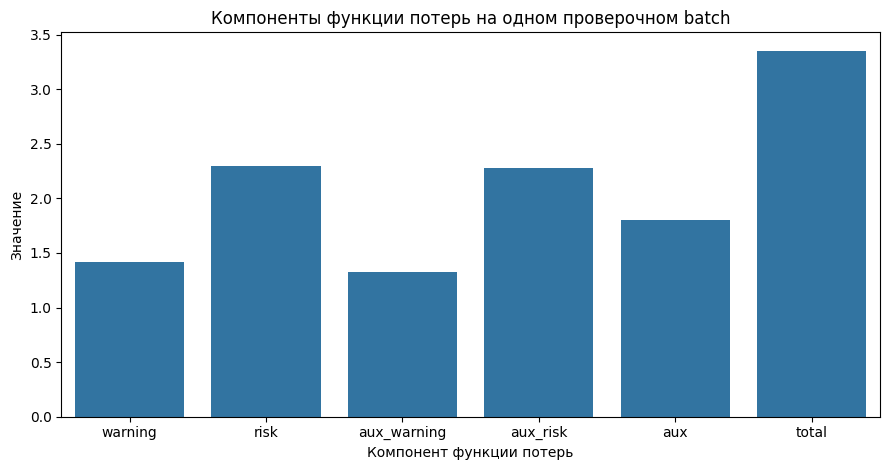

In [47]:
plot_df = pd.DataFrame(
    [
        {"loss_component": key, "loss_value": value}
        for key, value in dry_run_report["loss_parts"].items()
    ]
)

plt.figure(figsize=(9, 4.8))

sns.barplot(
    data=plot_df,
    x="loss_component",
    y="loss_value",
)

plt.title("Компоненты функции потерь на одном проверочном batch")
plt.xlabel("Компонент функции потерь")
plt.ylabel("Значение")
plt.tight_layout()
plt.show()

### Выводы по разделу

Проверка на одном mini-batch подтвердила, что подготовленные в разделе preprocessing входы совместимы с архитектурой central fusion-модели. Модель принимает все необходимые блоки признаков, формирует выходы для двух целевых переменных и возвращает значение gate для объединения логовой и KPI-ветвей.

Функция потерь имеет конечное значение, а backward pass формирует ненулевые градиенты. Это означает, что вычислительный граф корректно связывает входные tensors, fusion-блок и выходные головы. Следовательно, модель можно использовать в полном протоколе обучения без дополнительной ручной проверки размерностей.

График компонентов функции потерь показывает, что в проверочном запуске участвуют обе основные задачи: `y_warning` и `y_risk`. Вспомогательная часть функции потерь также вычисляется, но её роль остаётся регуляризующей. На этом этапе значения loss не интерпретируются как качество модели, потому что параметры ещё не проходили обучение.

## 7. Полный протокол обучения и оценка модели

В этом разделе выполняется полный экспериментальный запуск central fusion-модели. В режиме `debug` обучение не запускается: предыдущие разделы уже проверяют загрузку данных, preprocessing и прохождение одного batch через модель. В режиме `train` выполняется полный цикл: обучение на train-части, выбор порогов по validation, оценка на test и проверка вклада модальностей.

Качество модели оценивается отдельно для двух целевых переменных: `y_warning` и `y_risk`. Основной акцент делается на `Average Precision`, потому что положительный класс встречается реже отрицательного, и обычная accuracy в такой постановке была бы малоинформативной.

### 7.1. Функции обучения и оценки

Эта ячейка задаёт вспомогательные функции для обучения, выбора порогов, расчёта метрик и проверки ablation-сценариев. Сами вычисления запускаются в следующей ячейке только при `RUN_FULL_TRAINING = True`.

In [48]:
try:
    from tqdm.auto import tqdm
except Exception:
    tqdm = None


def safe_pr_auc(y_true, score):
    y_true = np.asarray(y_true).astype(int)

    if len(np.unique(y_true)) < 2:
        return None

    return float(average_precision_score(y_true, score))


def safe_roc_auc(y_true, score):
    y_true = np.asarray(y_true).astype(int)

    if len(np.unique(y_true)) < 2:
        return None

    return float(roc_auc_score(y_true, score))


def binary_metrics_at_threshold(y_true, score, threshold):
    y_true = np.asarray(y_true).astype(int)
    score = np.asarray(score)

    pred = (score >= threshold).astype(int)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        pred,
        average="binary",
        zero_division=0,
    )

    return {
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "threshold": float(threshold),
    }


def select_threshold_on_val(y_true, score, objective="f1", min_recall=None):
    y_true = np.asarray(y_true).astype(int)
    score = np.asarray(score)

    if len(np.unique(y_true)) < 2:
        return 0.5, {"reason": "validation target has one class"}

    thresholds = np.linspace(0.02, 0.98, 193)
    rows = []
    for threshold in thresholds:
        metrics = binary_metrics_at_threshold(y_true, score, threshold)
        rows.append({"threshold": float(threshold), **metrics})

    table = pd.DataFrame(rows)

    if objective == "risk_recall":
        min_recall = RISK_RECALL_TARGET if min_recall is None else float(min_recall)
        feasible = table[table["recall"] >= min_recall].copy()
        if feasible.empty:
            feasible = table.sort_values(["recall", "f1", "precision"], ascending=False).head(1).copy()
            reason = "no threshold reached requested recall"
        else:
            feasible = feasible.sort_values(["f1", "precision", "threshold"], ascending=[False, False, True]).head(1).copy()
            reason = "max f1 under recall constraint"
        best = feasible.iloc[0]
        return float(best["threshold"]), {
            "objective": objective,
            "risk_recall_target": float(min_recall),
            "best_val_f1": float(best["f1"]),
            "best_val_recall": float(best["recall"]),
            "best_val_precision": float(best["precision"]),
            "reason": reason,
        }

    best_idx = int(table["f1"].to_numpy().argmax())
    best = table.iloc[best_idx]
    return float(best["threshold"]), {"objective": objective, "best_val_f1": float(best["f1"])}


def monitor_score_from_metrics(ap_warning, ap_risk, risk_recall):
    ap_warning = 0.0 if ap_warning is None or not math.isfinite(float(ap_warning)) else float(ap_warning)
    ap_risk = 0.0 if ap_risk is None or not math.isfinite(float(ap_risk)) else float(ap_risk)
    risk_recall = 0.0 if risk_recall is None or not math.isfinite(float(risk_recall)) else float(risk_recall)
    return (
        MONITOR_WEIGHTS["ap_warning"] * ap_warning
        + MONITOR_WEIGHTS["ap_risk"] * ap_risk
        + MONITOR_WEIGHTS["risk_recall"] * risk_recall
    )


@torch.no_grad()
def predict_central_model(model, dataset, batch_size=BATCH_SIZE, device=None, ablation=None):
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    model.eval()
    rows = []

    for batch in loader:
        if ablation == "force_no_kpi":
            batch["kpi_tensor"] = torch.zeros_like(batch["kpi_tensor"])
            batch["kpi_micro"] = torch.zeros_like(batch["kpi_micro"])
            batch["masks"] = batch["masks"].clone()
            batch["masks"][:, 1] = 0.0

            if batch["masks"].shape[1] > 2:
                batch["masks"][:, 2] = 0.0

        elif ablation == "force_no_log":
            batch["log_embedding"] = torch.zeros_like(batch["log_embedding"])
            batch["log_macro"] = torch.zeros_like(batch["log_macro"])
            batch["log_micro"] = torch.zeros_like(batch["log_micro"])
            batch["masks"] = batch["masks"].clone()
            batch["masks"][:, 0] = 0.0

            if batch["masks"].shape[1] > 2:
                batch["masks"][:, 2] = 0.0

        elif ablation == "availability_only":
            batch["log_embedding"] = torch.zeros_like(batch["log_embedding"])
            batch["log_macro"] = torch.zeros_like(batch["log_macro"])
            batch["log_micro"] = torch.zeros_like(batch["log_micro"])
            batch["kpi_tensor"] = torch.zeros_like(batch["kpi_tensor"])
            batch["kpi_micro"] = torch.zeros_like(batch["kpi_micro"])

        batch = move_batch_to_device(batch, device)
        outputs = model(batch)

        rows.append(
            pd.DataFrame(
                {
                    "row_index": batch["row_index"].detach().cpu().numpy(),
                    "warning_score": torch.sigmoid(outputs["warning_logit"]).detach().cpu().numpy(),
                    "risk_score": torch.sigmoid(outputs["risk_logit"]).detach().cpu().numpy(),
                    "fusion_gate": outputs["gate"].detach().cpu().numpy(),
                    "y_warning": batch["y_warning"].detach().cpu().numpy(),
                    "y_risk": batch["y_risk"].detach().cpu().numpy(),
                }
            )
        )

    return pd.concat(rows, ignore_index=True)


@torch.no_grad()
def evaluate_loss_on_dataset(model, dataset, pos_weights, batch_size=BATCH_SIZE, device=None):
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    model.eval()
    losses = []

    for batch in loader:
        batch = move_batch_to_device(batch, device)
        outputs = model(batch)
        loss, _ = central_multitask_loss(outputs, batch, pos_weights)
        losses.append(float(loss.detach().cpu().item()))

    return float(np.mean(losses)) if losses else None


def train_central_model(model, train_dataset, val_dataset, pos_weights, device=None, seed=SEED, experiment_name="central_fusion"):
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    generator = torch.Generator()
    generator.manual_seed(int(seed))

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )

    best_state = None
    best_epoch = -1
    best_score = -np.inf
    patience_left = PATIENCE

    history = []
    milestones = []

    epoch_iter = range(1, MAX_EPOCHS + 1)

    if tqdm is not None:
        epoch_iter = tqdm(
            epoch_iter,
            total=MAX_EPOCHS,
            desc=f"Training {experiment_name} seed={seed}",
            leave=True,
        )

    for epoch in epoch_iter:
        model.train()
        train_losses = []

        batch_iter = train_loader

        if tqdm is not None:
            batch_iter = tqdm(
                train_loader,
                desc=f"Epoch {epoch}/{MAX_EPOCHS}",
                leave=False,
            )

        for batch in batch_iter:
            batch = move_batch_to_device(batch, device)

            optimizer.zero_grad(set_to_none=True)
            outputs = model(batch)
            loss, _ = central_multitask_loss(outputs, batch, pos_weights)

            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            optimizer.step()

            batch_loss = float(loss.detach().cpu().item())
            train_losses.append(batch_loss)

            if tqdm is not None:
                batch_iter.set_postfix(
                    {
                        "batch_loss": f"{batch_loss:.4f}",
                    }
                )

        train_loss = float(np.mean(train_losses))

        val_loss = evaluate_loss_on_dataset(
            model,
            val_dataset,
            pos_weights,
            batch_size=BATCH_SIZE,
            device=device,
        )

        val_pred = predict_central_model(
            model,
            val_dataset,
            batch_size=BATCH_SIZE,
            device=device,
        )

        val_pr_warning = safe_pr_auc(
            val_pred["y_warning"],
            val_pred["warning_score"],
        )

        val_pr_risk = safe_pr_auc(
            val_pred["y_risk"],
            val_pred["risk_score"],
        )

        risk_threshold_for_monitor, _ = select_threshold_on_val(
            val_pred["y_risk"],
            val_pred["risk_score"],
            objective="risk_recall",
            min_recall=RISK_RECALL_TARGET,
        )
        val_risk_recall = binary_metrics_at_threshold(
            val_pred["y_risk"],
            val_pred["risk_score"],
            risk_threshold_for_monitor,
        )["recall"]
        monitor_score = monitor_score_from_metrics(val_pr_warning, val_pr_risk, val_risk_recall)
        improved = monitor_score > best_score + 1e-5

        if improved:
            best_score = monitor_score
            best_epoch = epoch
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            patience_left = PATIENCE

            milestone = {
                "epoch": epoch,
                "event": "new_best_epoch",
                "monitor_metric": "0.4*AP_warning + 0.4*AP_risk + 0.2*risk_recall",
                "value": float(best_score),
                "seed": int(seed),
                "experiment": experiment_name,
            }

            milestones.append(milestone)

            if tqdm is not None:
                tqdm.write(
                    f"Epoch {epoch}: new best val_pr_warning={best_score:.4f}"
                )
        else:
            patience_left -= 1

        history.append(
            {
                "epoch": epoch,
                "train_loss": train_loss,
                "val_loss": val_loss,
                "val_pr_warning": val_pr_warning,
                "val_pr_risk": val_pr_risk,
                "val_risk_recall": float(val_risk_recall),
                "risk_threshold_for_monitor": float(risk_threshold_for_monitor),
                "monitor_score": monitor_score if np.isfinite(monitor_score) else None,
                "best_monitor_score": best_score if np.isfinite(best_score) else None,
                "improved": bool(improved),
                "patience_left": int(patience_left),
                "learning_rate": float(LEARNING_RATE),
            }
        )

        postfix = {
            "train_loss": f"{train_loss:.4f}",
            "val_loss": f"{val_loss:.4f}" if val_loss is not None else "nan",
            "val_pr_warning": f"{val_pr_warning:.4f}" if val_pr_warning is not None else "nan",
            "val_pr_risk": f"{val_pr_risk:.4f}" if val_pr_risk is not None else "nan",
            "best_epoch": best_epoch,
            "patience": patience_left,
        }

        if tqdm is not None:
            epoch_iter.set_postfix(postfix)
        else:
            print(f"Epoch {epoch}/{MAX_EPOCHS}: {postfix}")

        if patience_left <= 0:
            milestones.append(
                {
                    "epoch": epoch,
                    "event": "early_stopping",
                    "monitor_metric": "0.4*AP_warning + 0.4*AP_risk + 0.2*risk_recall",
                    "value": float(best_score),
                }
            )

            if tqdm is not None:
                tqdm.write(
                    f"Early stopping at epoch {epoch}. Best epoch: {best_epoch}."
                )

            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return {
        "model": model,
        "best_state": best_state,
        "best_epoch": best_epoch,
        "best_score": best_score,
        "history": pd.DataFrame(history),
        "milestones": pd.DataFrame(milestones),
        "seed": int(seed),
        "experiment": experiment_name,
    }


def make_prediction_table(pred_df, source_df, threshold_warning, threshold_risk):
    meta_cols = [
        "run_id",
        "window_ts",
        "split",
        "workload",
        "scenario",
        "scenario_type",
        "failure_family",
        "anchor_policy",
        "log_available",
        "kpi_available",
        "has_both_modalities",
        "kpi_avail_ratio",
    ]

    row_index = pred_df["row_index"].astype(int).to_numpy()
    meta = source_df.iloc[row_index][meta_cols].reset_index(drop=True)

    out = pd.concat(
        [
            meta,
            pred_df[
                [
                    "row_index",
                    "y_warning",
                    "y_risk",
                    "warning_score",
                    "risk_score",
                    "fusion_gate",
                ]
            ].reset_index(drop=True),
        ],
        axis=1,
    )

    out["threshold_warning"] = threshold_warning
    out["threshold_risk"] = threshold_risk
    out["pred_warning"] = (out["warning_score"] >= threshold_warning).astype(int)
    out["pred_risk"] = (out["risk_score"] >= threshold_risk).astype(int)

    out["pred_state"] = np.where(
        out["pred_risk"] == 1,
        "risk",
        np.where(out["pred_warning"] == 1, "warning", "normal"),
    )

    return out


def evaluate_prediction_table(table, target, score_col, threshold, slice_name="all"):
    y_true = table[target].astype(int).to_numpy()
    score = table[score_col].to_numpy()

    result = {
        "target": target,
        "slice": slice_name,
        "n": int(len(table)),
        "positives": int(y_true.sum()),
        "prevalence": float(y_true.mean()) if len(y_true) else None,
        "average_precision": safe_pr_auc(y_true, score),
        "roc_auc": safe_roc_auc(y_true, score),
    }

    result.update(
        binary_metrics_at_threshold(
            y_true,
            score,
            threshold,
        )
    )

    return result


def evaluate_by_slice(prediction_table, threshold_warning, threshold_risk):
    slice_specs = [
        ("all", np.ones(len(prediction_table), dtype=bool)),
        ("both", prediction_table["has_both_modalities"].astype(int).to_numpy() == 1),
        (
            "kpi_only",
            (prediction_table["kpi_available"].astype(int).to_numpy() == 1)
            & (prediction_table["log_available"].astype(int).to_numpy() == 0),
        ),
        ("kpi_available=1", prediction_table["kpi_available"].astype(int).to_numpy() == 1),
        ("has_both_modalities=1", prediction_table["has_both_modalities"].astype(int).to_numpy() == 1),
    ]
    for workload in sorted(prediction_table["workload"].dropna().unique().tolist()):
        slice_specs.append((f"workload={workload}", prediction_table["workload"].eq(workload).to_numpy()))

    rows = []

    for slice_name, mask in slice_specs:
        part = prediction_table.loc[mask].copy()

        if part.empty:
            continue

        rows.append(
            evaluate_prediction_table(
                part,
                target="y_warning",
                score_col="warning_score",
                threshold=threshold_warning,
                slice_name=slice_name,
            )
        )

        rows.append(
            evaluate_prediction_table(
                part,
                target="y_risk",
                score_col="risk_score",
                threshold=threshold_risk,
                slice_name=slice_name,
            )
        )

    return pd.DataFrame(rows)


def run_modality_ablation(model, test_dataset, source_df, threshold_warning, threshold_risk):
    rows = []

    for ablation_name, ablation_key in [
        ("central_fused", None),
        ("neural_log_only", "force_no_kpi"),
        ("neural_kpi_only", "force_no_log"),
        ("availability_only", "availability_only"),
    ]:
        pred = predict_central_model(
            model,
            test_dataset,
            batch_size=BATCH_SIZE,
            device=device,
            ablation=ablation_key,
        )

        table = make_prediction_table(
            pred,
            source_df,
            threshold_warning,
            threshold_risk,
        )

        metrics = evaluate_by_slice(
            table,
            threshold_warning,
            threshold_risk,
        )

        metrics["ablation"] = ablation_name
        rows.append(metrics)

    return pd.concat(rows, ignore_index=True)


def build_gate_summary(prediction_table):
    modality_case = np.select(
        [
            prediction_table["has_both_modalities"].astype(int).eq(1),
            prediction_table["log_available"].astype(int).eq(1),
            prediction_table["kpi_available"].astype(int).eq(1),
        ],
        [
            "both_modalities",
            "log_only",
            "kpi_only",
        ],
        default="no_modality",
    )

    gate_summary = (
        prediction_table
        .assign(modality_case=modality_case)
        .groupby("modality_case", dropna=False)["fusion_gate"]
        .agg(["count", "mean", "std"])
        .reset_index()
    )

    return gate_summary


# --- Compact artifact helpers for section 7-8 ---
CENTRAL_MODEL_NAME = "central-fusion-model"

COMPACT_MODEL_BUNDLE_FILES = [
    "central_model.pt",
    "preprocessing_artifacts.joblib",
    "central_model_metrics.json",
    "baseline_comparison.csv",
    "model_card_central_fusion.md",
    "inference_manifest.json",
    "dashboard_model_report.json",
    "dashboard_replay_store.csv",
    "seed_metrics.csv",
    "calibration_bins.csv",
]

TARGET_LABELS_RU = {
    "y_warning": "Предупреждение",
    "y_risk": "Риск",
}

MODEL_LABELS_RU = {
    CENTRAL_MODEL_NAME: "central fusion",
    "fused": "Baseline: fused",
    "log-only": "Baseline: log-only",
    "kpi-only": "Baseline: KPI-only",
    "availability-only": "Baseline: availability-only",
    "prevalence": "Baseline: prevalence",
}

ABLATION_LABELS_RU = {
    "central_fused": "Central fused",
    "neural_log_only": "Neural log-only",
    "neural_kpi_only": "Neural KPI-only",
    "availability_only": "Availability-only",
}


def _finite_or_none(value):
    try:
        value = float(value)
    except Exception:
        return None

    return value if math.isfinite(value) else None


def _metric_delta_text(delta, tolerance=0.01):
    delta = _finite_or_none(delta)

    if delta is None:
        return "нет сравнения"

    if delta > tolerance:
        return "выше лучшего baseline"

    if delta < -tolerance:
        return "ниже лучшего baseline"

    return "сопоставимо с лучшим baseline"


def build_baseline_comparison(metrics_df, baseline_summary):
    metric_cols = [
        "target",
        "slice",
        "n",
        "positives",
        "prevalence",
        "average_precision",
        "roc_auc",
        "precision",
        "recall",
        "f1",
        "threshold",
    ]

    central = metrics_df.loc[metrics_df["slice"].eq("all")].copy()
    central["model"] = CENTRAL_MODEL_NAME
    central["source"] = "notebook_03"
    central["status"] = "trained"
    central["uses_text"] = True
    central["numeric_features"] = np.nan

    baseline = pd.DataFrame(baseline_summary.get("baseline_metrics", []))
    if baseline.empty:
        baseline = pd.DataFrame(columns=metric_cols + ["baseline", "status"])

    if "status" not in baseline.columns:
        baseline["status"] = "ok"
    baseline = baseline.loc[baseline["status"].fillna("ok").eq("ok")].copy()
    baseline = baseline.rename(columns={"baseline": "model"})
    baseline["source"] = "notebook_02"
    baseline["slice"] = "all"

    for frame in [central, baseline]:
        for col in metric_cols + ["model", "source", "status", "uses_text", "numeric_features"]:
            if col not in frame.columns:
                frame[col] = np.nan

    combined = pd.concat(
        [
            central[metric_cols + ["model", "source", "status", "uses_text", "numeric_features"]],
            baseline[metric_cols + ["model", "source", "status", "uses_text", "numeric_features"]],
        ],
        ignore_index=True,
    )

    for col in ["average_precision", "roc_auc", "precision", "recall", "f1", "threshold", "prevalence"]:
        combined[col] = pd.to_numeric(combined[col], errors="coerce")

    best_by_target = {}
    baseline_only = combined.loc[combined["source"].eq("notebook_02")].copy()

    for target, part in baseline_only.groupby("target", dropna=False):
        ranked = part.sort_values("average_precision", ascending=False)
        if ranked.empty:
            continue

        row = ranked.iloc[0]
        best_by_target[target] = {
            "best_baseline_model": row["model"],
            "best_baseline_average_precision": _finite_or_none(row["average_precision"]),
            "best_baseline_f1": _finite_or_none(row["f1"]),
        }

    combined["best_baseline_model"] = combined["target"].map(
        lambda target: best_by_target.get(target, {}).get("best_baseline_model")
    )
    combined["best_baseline_average_precision"] = combined["target"].map(
        lambda target: best_by_target.get(target, {}).get("best_baseline_average_precision")
    )
    combined["best_baseline_f1"] = combined["target"].map(
        lambda target: best_by_target.get(target, {}).get("best_baseline_f1")
    )

    central_mask = combined["model"].eq(CENTRAL_MODEL_NAME)
    combined["delta_ap_vs_best_baseline"] = np.nan
    combined["delta_f1_vs_best_baseline"] = np.nan
    combined.loc[central_mask, "delta_ap_vs_best_baseline"] = (
        combined.loc[central_mask, "average_precision"]
        - combined.loc[central_mask, "best_baseline_average_precision"]
    )
    combined.loc[central_mask, "delta_f1_vs_best_baseline"] = (
        combined.loc[central_mask, "f1"]
        - combined.loc[central_mask, "best_baseline_f1"]
    )

    combined["target_label"] = combined["target"].map(TARGET_LABELS_RU).fillna(combined["target"])
    combined["model_label"] = combined["model"].map(MODEL_LABELS_RU).fillna(combined["model"])
    combined["interpretation"] = combined["delta_ap_vs_best_baseline"].map(_metric_delta_text)

    model_order = {
        CENTRAL_MODEL_NAME: 0,
        "fused": 1,
        "log-only": 2,
        "kpi-only": 3,
        "availability-only": 4,
        "prevalence": 5,
    }
    combined["model_order"] = combined["model"].map(model_order).fillna(99).astype(int)

    return (
        combined
        .sort_values(["target", "model_order", "source"])
        .drop(columns=["model_order"])
        .reset_index(drop=True)
    )


def build_ablation_summary(ablation_df):
    out = ablation_df.loc[ablation_df["slice"].eq("all")].copy()

    if out.empty:
        return out

    for col in ["average_precision", "roc_auc", "precision", "recall", "f1"]:
        out[col] = pd.to_numeric(out[col], errors="coerce")

    central = (
        out.loc[out["ablation"].eq("central_fused"), ["target", "average_precision", "f1"]]
        .rename(columns={"average_precision": "central_fused_average_precision", "f1": "central_fused_f1"})
    )
    out = out.merge(central, on="target", how="left")
    out["delta_ap_vs_central_fused"] = out["average_precision"] - out["central_fused_average_precision"]
    out["delta_f1_vs_central_fused"] = out["f1"] - out["central_fused_f1"]
    out["target_label"] = out["target"].map(TARGET_LABELS_RU).fillna(out["target"])
    out["ablation_label"] = out["ablation"].map(ABLATION_LABELS_RU).fillna(out["ablation"])

    return out.reset_index(drop=True)


def build_training_summary_table(
    history_df,
    best_epoch,
    threshold_warning,
    threshold_risk,
    device,
    model_parameter_count,
    best_seed=None,
    best_score=None,
):
    stopped_epoch = int(history_df["epoch"].max()) if len(history_df) else None
    best_row = history_df.loc[history_df["epoch"].eq(best_epoch)].copy()
    best_val_warning = None
    best_val_risk = None

    if not best_row.empty:
        best_val_warning = _finite_or_none(best_row.iloc[0].get("val_pr_warning"))
        best_val_risk = _finite_or_none(best_row.iloc[0].get("val_pr_risk"))

    rows = [
        {"Показатель": "Режим запуска", "Значение": RUN_MODE},
        {"Показатель": "Устройство", "Значение": str(device)},
        {"Показатель": "Train окон", "Значение": int(len(train_idx))},
        {"Показатель": "Validation окон", "Значение": int(len(val_idx))},
        {"Показатель": "Test окон", "Значение": int(len(test_idx))},
        {"Показатель": "Лучшая эпоха", "Значение": int(best_epoch)},
            {"Показатель": "Лучший seed", "Значение": int(best_seed) if best_seed is not None else None},
            {"Показатель": "Best monitor score", "Значение": _finite_or_none(best_score)},
        {"Показатель": "Эпоха остановки", "Значение": stopped_epoch},
        {"Показатель": "Максимум эпох", "Значение": int(MAX_EPOCHS)},
        {"Показатель": "Threshold y_warning", "Значение": float(threshold_warning)},
        {"Показатель": "Threshold y_risk", "Значение": float(threshold_risk)},
        {"Показатель": "Best val AP y_warning", "Значение": best_val_warning},
        {"Показатель": "Val AP y_risk на best epoch", "Значение": best_val_risk},
        {"Показатель": "Обучаемых параметров", "Значение": int(model_parameter_count)},
        {"Показатель": "Текстовый encoder", "Значение": text_manifest.get("encoder_name")},
    ]

    return pd.DataFrame(rows)


def build_robustness_summary(run_metric_df):
    if run_metric_df.empty:
        return pd.DataFrame()
    all_slice = run_metric_df[run_metric_df["slice"].eq("all")].copy()
    return (
        all_slice.groupby(["experiment", "target"], as_index=False)
        .agg(
            seeds=("seed", "nunique"),
            average_precision_mean=("average_precision", "mean"),
            average_precision_std=("average_precision", "std"),
            f1_mean=("f1", "mean"),
            f1_std=("f1", "std"),
            recall_mean=("recall", "mean"),
            recall_std=("recall", "std"),
        )
    )


def build_inference_manifest():
    return {
        "bundle_version": "raw_central_model_v1",
        "purpose": "research_inference_bundle_for_vkr_dashboard",
        "input_boundary": (
            "Модель принимает не raw_data напрямую, а aligned multi-rate contract, "
            "собранный теми же правилами, что outputs/raw_multirate/aligned_multirate_windows.csv."
        ),
        "pipeline": [
            "raw_data/<workload>/...",
            "сбор логов и KPI в strict multi-rate contract по правилам notebook 02",
            "preprocessing из preprocessing_artifacts.joblib",
            "CentralFusionMultiRate из central_model.pt",
            "warning_score, risk_score, pred_state",
        ],
        "required_artifacts": {
            "model": str((OUT_ROOT / "central_model.pt").relative_to(ROOT)),
            "preprocessing": str((OUT_ROOT / "preprocessing_artifacts.joblib").relative_to(ROOT)),
            "metrics": str((OUT_ROOT / "central_model_metrics.json").relative_to(ROOT)),
            "feature_manifest": str((OUT_ROOT / "feature_manifest.json").relative_to(ROOT)),
        },
        "required_contract_columns": {
            "identity": ["run_id", "window_ts", "workload", "scenario", "split"],
            "targets_for_evaluation": TARGET_COLS,
            "log_macro": LOG_MACRO_COLS,
            "log_micro": LOG_MICRO_COLS,
            "model_masks": MODEL_MASK_COLS,
            "kpi_micro": KPI_MICRO_COLS,
            "kpi_series_order": selected_series,
            "kpi_stat_order": STAT_ORDER,
            "text": ["log_text"],
        },
        "output_schema": {
            "warning_score": "float [0, 1]",
            "risk_score": "float [0, 1]",
            "pred_warning": "int, thresholded by threshold_warning",
            "pred_risk": "int, thresholded by threshold_risk",
            "pred_state": "normal | warning | risk",
            "fusion_gate": "float [0, 1], larger values mean larger log-branch contribution",
        },
        "thresholds": {
            "warning": None,
            "risk": None,
        },
        "notes": [
            "Сырые raw_data должны быть предварительно приведены к тому же набору окон и колонок.",
            "Notebook 03 не создаёт legacy outputs/lcman/*: старый dashboard не является финальным контрактом.",
        ],
    }


def build_model_card(metrics_payload, comparison_df, inference_manifest):
    central = comparison_df.loc[comparison_df["model"].eq(CENTRAL_MODEL_NAME)].copy()
    lines = [
        "# Карточка модели central fusion",
        "",
        "## Назначение",
        "Модель используется как исследовательский scorer для оценки состояний `Предупреждение` и `Риск` по multimodal telemetry: логам, KPI и признакам доступности модальностей.",
        "",
        "## Данные и split",
        f"- Контракт: `{metrics_payload.get('contract_path')}`.",
        f"- Train / validation / test: {metrics_payload.get('train_rows')} / {metrics_payload.get('validation_rows')} / {metrics_payload.get('test_rows')} окон.",
        f"- Test workloads: {', '.join(metrics_payload.get('test_workloads', []))}.",
        "- Split является workload-holdout; результаты нельзя трактовать как online-production benchmark.",
        "",
        "## Обучение",
        f"- Лучшая эпоха: {metrics_payload.get('best_epoch')}.",
        f"- Threshold warning: {metrics_payload.get('threshold_warning'):.3f}.",
        f"- Threshold risk: {metrics_payload.get('threshold_risk'):.3f}.",
        f"- Число обучаемых параметров: {metrics_payload.get('model_parameter_count'):,}.",
        "",
        "## Сравнение с baseline",
    ]

    if central.empty:
        lines.append("Сравнение недоступно: строки central fusion отсутствуют в baseline comparison.")
    else:
        for _, row in central.iterrows():
            target_label = row.get("target_label", row.get("target"))
            ap = _finite_or_none(row.get("average_precision"))
            best_model = row.get("best_baseline_model")
            best_ap = _finite_or_none(row.get("best_baseline_average_precision"))
            delta = _finite_or_none(row.get("delta_ap_vs_best_baseline"))
            verdict = _metric_delta_text(delta)
            lines.append(
                f"- {target_label}: AP={ap:.4f}; лучший baseline `{best_model}` AP={best_ap:.4f}; delta={delta:+.4f} ({verdict})."
            )

    lines.extend(
        [
            "",
            "## Inference boundary",
            inference_manifest["input_boundary"],
            "",
            "## Ограничения",
            "- Targets унаследованы от proxy-разметки notebook 02.",
            "- Failure anchors могут включать run_end_proxy, поэтому время отказа не всегда является истинной меткой события.",
            "- Признаки доступности модальностей могут выступать shortcut-сигналом.",
            "- Для финальной оценки желательны repeated seeds и отдельная проверка калибровки порогов.",
        ]
    )

    return "\n".join(lines) + "\n"


### 7.2. Запуск полного обучения

Эта ячейка запускает обучение только в режиме `train`. Во время выполнения будет показан индикатор прогресса: он обновляется по эпохам и показывает текущие значения `train_loss`, `val_loss`, `val_pr_warning`, `val_pr_risk`, лучшую эпоху и оставшийся запас patience.

В режиме `debug` ячейка не обучает модель, а только фиксирует, что полный запуск пропущен.

In [49]:
training_outputs = {
    "status": "skipped_debug" if not RUN_FULL_TRAINING else "pending"
}

if not RUN_FULL_TRAINING:
    display(
        Markdown(
            """
**Полное обучение не запускалось.**

Notebook сейчас находится в режиме `debug`, поэтому этот раздел не обучает модель и не создаёт compact model bundle. Для полного запуска нужно переключить режим на `train` в начальной ячейке и выполнить notebook заново на машине для обучения.
"""
        )
    )

else:
    if "arrays" not in globals():
        raise RuntimeError("Сначала выполните preprocessing: словарь arrays не создан.")
    if "model_config" not in globals():
        raise RuntimeError("Сначала выполните проверку графа: model_config не создан.")
    if joblib is None:
        raise RuntimeError("Для сохранения preprocessing_artifacts.joblib требуется пакет joblib.")

    from dashboard.model_report import write_dashboard_diagnostics

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    train_dataset_full = CentralFusionDataset(arrays, train_idx)
    val_dataset = CentralFusionDataset(arrays, val_idx)
    test_dataset = CentralFusionDataset(arrays, test_idx)

    pos_weights_full = {
        "warning": torch.tensor(compute_pos_weight(arrays["y_warning"][train_idx]), dtype=torch.float32, device=device),
        "risk": torch.tensor(compute_pos_weight(arrays["y_risk"][train_idx]), dtype=torch.float32, device=device),
    }

    experiment_specs = [
        {
            "experiment": "central_fusion",
            "label": "central fusion attention",
            "config_overrides": {"model_name": "central_fusion_multirate", "kpi_pooling": "attention", "fusion_mode": "attention"},
            "seeds": TRAIN_SEEDS,
            "primary": True,
        }
    ]
    if RUN_ARCHITECTURE_ABLATION:
        experiment_specs.extend(
            [
                {
                    "experiment": "current_pooling_gate",
                    "label": "Current mean/max pooling + gate",
                    "config_overrides": {"model_name": "current_pooling_gate", "kpi_pooling": "mean_max", "fusion_mode": "gate"},
                    "seeds": [SEED],
                    "primary": False,
                },
                {
                    "experiment": "attention_pooling_gate",
                    "label": "KPI attention pooling + gate",
                    "config_overrides": {"model_name": "attention_pooling_gate", "kpi_pooling": "attention", "fusion_mode": "gate"},
                    "seeds": [SEED],
                    "primary": False,
                },
            ]
        )

    run_results = []
    run_metric_frames = []

    for spec in experiment_specs:
        for seed in spec["seeds"]:
            set_seed(seed)
            run_config = model_config.copy()
            run_config.update(spec["config_overrides"])
            run_config["seed"] = int(seed)
            run_config["experiment"] = spec["experiment"]
            run_model = CentralFusionMultiRate(run_config).to(device)
            training_result_run = train_central_model(
                run_model,
                train_dataset_full,
                val_dataset,
                pos_weights_full,
                device=device,
                seed=seed,
                experiment_name=spec["experiment"],
            )
            if training_result_run["best_state"] is None:
                raise RuntimeError(f"Обучение {spec['experiment']} seed={seed} завершилось без best_state.")

            val_pred_run = predict_central_model(training_result_run["model"], val_dataset, batch_size=BATCH_SIZE, device=device)
            threshold_warning_run, warning_thr_info_run = select_threshold_on_val(
                val_pred_run["y_warning"], val_pred_run["warning_score"], objective="f1"
            )
            threshold_risk_run, risk_thr_info_run = select_threshold_on_val(
                val_pred_run["y_risk"],
                val_pred_run["risk_score"],
                objective="risk_recall",
                min_recall=RISK_RECALL_TARGET,
            )
            test_pred_run = predict_central_model(training_result_run["model"], test_dataset, batch_size=BATCH_SIZE, device=device)
            prediction_table_run = make_prediction_table(test_pred_run, df, threshold_warning_run, threshold_risk_run)
            metrics_df_run = evaluate_by_slice(prediction_table_run, threshold_warning_run, threshold_risk_run)
            metrics_df_run["experiment"] = spec["experiment"]
            metrics_df_run["experiment_label"] = spec["label"]
            metrics_df_run["seed"] = int(seed)
            metrics_df_run["primary_experiment"] = bool(spec["primary"])
            run_metric_frames.append(metrics_df_run)
            run_results.append(
                {
                    **training_result_run,
                    "config": run_config,
                    "threshold_warning": float(threshold_warning_run),
                    "threshold_risk": float(threshold_risk_run),
                    "threshold_selection": {"warning": warning_thr_info_run, "risk": risk_thr_info_run},
                    "metrics": metrics_df_run,
                    "prediction_table": prediction_table_run,
                    "experiment_label": spec["label"],
                    "primary_experiment": bool(spec["primary"]),
                }
            )

    all_run_metrics_df = pd.concat(run_metric_frames, ignore_index=True) if run_metric_frames else pd.DataFrame()
    robustness_summary_df = build_robustness_summary(all_run_metrics_df)
    architecture_ablation_df = all_run_metrics_df[all_run_metrics_df["slice"].eq("all")].copy()

    primary_results = [result for result in run_results if result["primary_experiment"]]
    training_result = max(primary_results, key=lambda result: result["best_score"])
    model_config.update(training_result["config"])
    model_config["model_parameter_count"] = int(count_parameters(training_result["model"]))

    history_df = training_result["history"]
    milestones_df = training_result["milestones"]
    threshold_warning = training_result["threshold_warning"]
    threshold_risk = training_result["threshold_risk"]
    prediction_table = training_result["prediction_table"]
    metrics_df = training_result["metrics"]

    ablation_df = run_modality_ablation(training_result["model"], test_dataset, df, threshold_warning, threshold_risk)
    ablation_summary_df = build_ablation_summary(ablation_df)
    gate_summary_df = build_gate_summary(prediction_table)
    baseline_comparison_df = build_baseline_comparison(metrics_df, baseline_summary)
    training_summary_df = build_training_summary_table(
        history_df=history_df,
        best_epoch=int(training_result["best_epoch"]),
        threshold_warning=threshold_warning,
        threshold_risk=threshold_risk,
        device=device,
        model_parameter_count=model_config["model_parameter_count"],
        best_seed=int(training_result["seed"]),
        best_score=float(training_result["best_score"]),
    )

    inference_manifest = build_inference_manifest()
    inference_manifest["thresholds"] = {"warning": float(threshold_warning), "risk": float(threshold_risk)}

    torch.save(
        {
            "state_dict": training_result["best_state"],
            "model_config": model_config,
            "feature_manifest": feature_manifest,
            "preprocessing_manifest": preprocessing_manifest,
            "threshold_warning": float(threshold_warning),
            "threshold_risk": float(threshold_risk),
            "split_passport": split_passport,
            "contract_path": str(CONTRACT_PATH.relative_to(ROOT)),
            "baseline_summary_path": str(BASELINE_SUMMARY_PATH.relative_to(ROOT)),
            "text_encoder": text_manifest,
            "seed": int(training_result["seed"]),
        },
        OUT_ROOT / "central_model.pt",
    )
    joblib.dump(
        {
            "text": preprocessing_artifacts.get("text"),
            "log_macro": preprocessing_artifacts.get("log_macro"),
            "log_micro": preprocessing_artifacts.get("log_micro"),
            "kpi_micro": preprocessing_artifacts.get("kpi_micro"),
            "kpi_tensor_stats": preprocessing_artifacts.get("kpi_tensor_stats"),
            "column_order": {
                "log_macro": LOG_MACRO_COLS,
                "log_micro": LOG_MICRO_COLS,
                "model_masks": MODEL_MASK_COLS,
                "kpi_micro": KPI_MICRO_COLS,
                "kpi_series": selected_series,
                "kpi_stat_order": STAT_ORDER,
            },
            "preprocessing_manifest": preprocessing_manifest,
        },
        OUT_ROOT / "preprocessing_artifacts.joblib",
    )

    baseline_comparison_df.to_csv(OUT_ROOT / "baseline_comparison.csv", index=False)
    all_run_metrics_df.to_csv(OUT_ROOT / "architecture_ablation_metrics.csv", index=False)
    robustness_summary_df.to_csv(OUT_ROOT / "robustness_summary.csv", index=False)
    write_json_safe(OUT_ROOT / "inference_manifest.json", inference_manifest)

    metrics_payload = {
        "run_full_training": True,
        "run_mode": RUN_MODE,
        "contract_path": str(CONTRACT_PATH.relative_to(ROOT)),
        "baseline_summary_path": str(BASELINE_SUMMARY_PATH.relative_to(ROOT)),
        "model_name": model_config.get("model_name"),
        "architecture": {"kpi_pooling": model_config.get("kpi_pooling"), "fusion_mode": model_config.get("fusion_mode")},
        "text_encoder": text_manifest,
        "seed": int(training_result["seed"]),
        "train_seeds": TRAIN_SEEDS,
        "device": str(device),
        "best_epoch": int(training_result["best_epoch"]),
        "best_monitor_score": float(training_result["best_score"]),
        "stopped_epoch": int(history_df["epoch"].max()) if len(history_df) else None,
        "max_epochs": int(MAX_EPOCHS),
        "patience": int(PATIENCE),
        "threshold_warning": float(threshold_warning),
        "threshold_risk": float(threshold_risk),
        "threshold_selection": training_result["threshold_selection"],
        "model_parameter_count": int(model_config["model_parameter_count"]),
        "train_rows": int(len(train_idx)),
        "validation_rows": int(len(val_idx)),
        "test_rows": int(len(test_idx)),
        "test_workloads": split_passport["test_workloads"],
        "training_summary": training_summary_df.to_dict(orient="records"),
        "training_history_tail": history_df.tail(8).to_dict(orient="records"),
        "training_milestones": milestones_df.to_dict(orient="records"),
        "primary_metrics": metrics_df.to_dict(orient="records"),
        "ablation_metrics": ablation_summary_df.to_dict(orient="records"),
        "architecture_ablation": architecture_ablation_df.to_dict(orient="records"),
        "robustness_summary": robustness_summary_df.to_dict(orient="records"),
        "gate_summary": gate_summary_df.to_dict(orient="records"),
        "baseline_comparison": baseline_comparison_df.to_dict(orient="records"),
        "bundle_artifacts": COMPACT_MODEL_BUNDLE_FILES,
        "limitations": [
            "Targets are inherited from proxy labels of notebook 02.",
            "Test quality should be interpreted under the workload-holdout split.",
            "Modality availability may act as a shortcut signal.",
            "EmbeddingGemma is an offline preprocessing dependency, not a runtime model dependency.",
        ],
    }
    write_json_safe(OUT_ROOT / "central_model_metrics.json", metrics_payload)
    model_card_text = build_model_card(metrics_payload, baseline_comparison_df, inference_manifest)
    (OUT_ROOT / "model_card_central_fusion.md").write_text(model_card_text, encoding="utf-8")

    baseline_predictions_path = ROOT / "outputs" / "raw_multirate" / "model_predictions_smoke.csv"
    baseline_predictions_df = pd.read_csv(baseline_predictions_path) if baseline_predictions_path.exists() else pd.DataFrame()
    seed_metrics_input = all_run_metrics_df.loc[
        all_run_metrics_df["primary_experiment"].astype(bool) & all_run_metrics_df["slice"].eq("all")
    ].copy()
    diagnostic_artifacts = write_dashboard_diagnostics(
        timeline=df,
        prediction_store=prediction_table,
        baseline_predictions=baseline_predictions_df,
        baseline_comparison=baseline_comparison_df,
        metrics_payload=metrics_payload,
        output_dir=OUT_ROOT,
        existing_seed_metrics=seed_metrics_input,
    )

    bundle_status_df = pd.DataFrame(
        [
            {"Артефакт": name, "Файл существует": (OUT_ROOT / name).exists(), "Путь": str((OUT_ROOT / name).relative_to(ROOT))}
            for name in COMPACT_MODEL_BUNDLE_FILES
        ]
    )

    training_outputs = {
        "status": "trained",
        "history": history_df,
        "milestones": milestones_df,
        "summary": training_summary_df,
        "metrics": metrics_df,
        "ablation": ablation_df,
        "ablation_summary": ablation_summary_df,
        "architecture_ablation": architecture_ablation_df,
        "robustness_summary": robustness_summary_df,
        "gate_summary": gate_summary_df,
        "prediction_table": prediction_table,
        "baseline_comparison": baseline_comparison_df,
        "inference_manifest": inference_manifest,
        "bundle_status": bundle_status_df,
        "dashboard_diagnostics": diagnostic_artifacts,
        "best_epoch": int(training_result["best_epoch"]),
        "best_seed": int(training_result["seed"]),
        "threshold_warning": float(threshold_warning),
        "threshold_risk": float(threshold_risk),
    }
    display(
        Markdown(
            f"""
**Полное обучение central fusion завершено, compact model bundle сохранён.**

- лучшая эпоха: **{training_outputs["best_epoch"]}**
- лучший seed: **{training_outputs["best_seed"]}**
- threshold для `y_warning`: **{training_outputs["threshold_warning"]:.3f}**
- threshold для `y_risk`: **{training_outputs["threshold_risk"]:.3f}**
- test-строк в оценке: **{len(prediction_table):,}**
- основной файл модели: `{(OUT_ROOT / "central_model.pt").relative_to(ROOT)}`
"""
        )
    )
    display(bundle_status_df)


Training central_fusion seed=42:   0%|          | 0/120 [00:00<?, ?it/s]

Epoch 1/120:   0%|          | 0/47 [00:00<?, ?it/s]

Epoch 1: new best val_pr_warning=0.4884


Epoch 2/120:   0%|          | 0/47 [00:00<?, ?it/s]

Epoch 2: new best val_pr_warning=0.5214


...

Epoch 18/120:   0%|          | 0/47 [00:00<?, ?it/s]

Epoch 19/120:   0%|          | 0/47 [00:00<?, ?it/s]

Epoch 20/120:   0%|          | 0/47 [00:00<?, ?it/s]

Early stopping at epoch 20. Best epoch: 6.


KeyError: 'baseline'

### 7.3. Динамика функции потерь

График показывает, как менялись `train_loss` и `val_loss` по эпохам. Если train loss уменьшается, а validation loss начинает расти, это может указывать на переобучение. Если обе кривые почти не меняются, модель может недообучаться или получать недостаточно информативные признаки.

In [50]:
if training_outputs["status"] == "trained":
    plot_df = (
        training_outputs["history"][
            ["epoch", "train_loss", "val_loss"]
        ]
        .melt(
            id_vars="epoch",
            var_name="loss_type",
            value_name="loss_value",
        )
    )

    plt.figure(figsize=(9, 4.8))

    sns.lineplot(
        data=plot_df,
        x="epoch",
        y="loss_value",
        hue="loss_type",
        marker="o",
    )

    plt.title("Динамика функции потерь во время обучения")
    plt.xlabel("Эпоха")
    plt.ylabel("Loss")
    plt.tight_layout()
    plt.show()

else:
    display(
        Markdown(
            "График динамики loss не строится, потому что полный режим обучения не был запущен."
        )
    )

График динамики loss не строится, потому что полный режим обучения не был запущен.

### 7.4. Динамика validation Average Precision

Этот график показывает, как менялась `Average Precision` на validation-части для двух целевых переменных. Метрика `val_pr_warning` используется для выбора лучшей эпохи, а `val_pr_risk` показывает, насколько стабильно обучается вторая целевая голова.

In [51]:
if training_outputs["status"] == "trained":
    plot_df = (
        training_outputs["history"][
            ["epoch", "val_pr_warning", "val_pr_risk"]
        ]
        .melt(
            id_vars="epoch",
            var_name="target_metric",
            value_name="average_precision",
        )
    )

    plt.figure(figsize=(9, 4.8))

    sns.lineplot(
        data=plot_df,
        x="epoch",
        y="average_precision",
        hue="target_metric",
        marker="o",
    )

    plt.axvline(
        training_outputs["best_epoch"],
        linestyle="--",
        linewidth=1,
    )

    plt.title("Validation Average Precision по эпохам")
    plt.xlabel("Эпоха")
    plt.ylabel("Average Precision")
    plt.tight_layout()
    plt.show()

else:
    display(
        Markdown(
            "График validation Average Precision не строится, потому что полный режим обучения не был запущен."
        )
    )

График validation Average Precision не строится, потому что полный режим обучения не был запущен.

### 7.5. Метрики на test-части

После выбора лучшей эпохи и порогов по validation модель оценивается на test-части. График показывает `Average Precision` для двух целевых переменных на общем test-срезе и на срезах по доступности модальностей.


In [52]:
if training_outputs["status"] == "trained":
    plot_df = training_outputs["metrics"].copy()
    plot_df = plot_df[plot_df["average_precision"].notna()]

    plt.figure(figsize=(9, 4.8))

    sns.barplot(
        data=plot_df,
        x="slice",
        y="average_precision",
        hue="target",
    )

    plt.title("Average Precision central fusion-модели на test split")
    plt.xlabel("Срез test-части")
    plt.ylabel("Average Precision")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

else:
    display(
        Markdown(
            "График test-метрик не строится, потому что полный режим обучения не был запущен."
        )
    )

График test-метрик не строится, потому что полный режим обучения не был запущен.

### 7.6. Каноническая таблица test-метрик и сравнение с baseline

Табличная форма нужна для академического отчёта: график показывает общую картину, а таблица фиксирует точные значения `Average Precision`, `ROC-AUC`, `precision`, `recall` и `F1`. Сравнение выполняется с baseline-метриками notebook 02 на том же test split.


In [53]:
if training_outputs["status"] == "trained":
    display(Markdown("**Сводка обучения и сохранения модели**"))
    display(training_outputs["summary"])

    metric_cols = [
        "target_label",
        "slice",
        "n",
        "positives",
        "prevalence",
        "average_precision",
        "roc_auc",
        "precision",
        "recall",
        "f1",
        "threshold",
    ]
    metrics_table = training_outputs["metrics"].copy()
    metrics_table["target_label"] = metrics_table["target"].map(TARGET_LABELS_RU)
    display(Markdown("**Метрики central fusion на test split**"))
    display(metrics_table[metric_cols].sort_values(["target_label", "slice"]))

    display(Markdown("**Robustness по seed-запускам**"))
    display(training_outputs["robustness_summary"])

    display(Markdown("**Architecture ablation: pooling/fusion варианты**"))
    arch_cols = [
        "experiment_label",
        "seed",
        "target",
        "n",
        "average_precision",
        "roc_auc",
        "precision",
        "recall",
        "f1",
    ]
    arch_table = training_outputs["architecture_ablation"].copy()
    display(arch_table[arch_cols].sort_values(["target", "experiment_label", "seed"]))

    comparison_cols = [
        "target_label",
        "model_label",
        "average_precision",
        "roc_auc",
        "precision",
        "recall",
        "f1",
        "best_baseline_model",
        "best_baseline_average_precision",
        "delta_ap_vs_best_baseline",
        "interpretation",
    ]
    comparison_table = training_outputs["baseline_comparison"].copy()
    display(Markdown("**Сравнение с baseline из notebook 02**"))
    display(comparison_table[comparison_cols])

    central_rows = comparison_table.loc[comparison_table["model"].eq(CENTRAL_MODEL_NAME)]
    conclusion_lines = []
    for _, row in central_rows.iterrows():
        conclusion_lines.append(
            f"- {row['target_label']}: delta AP к лучшему baseline = {row['delta_ap_vs_best_baseline']:+.4f}; {row['interpretation']}."
        )

    display(
        Markdown(
            "**Локальный вывод.** Таблица фиксирует качество central fusion в сопоставимом виде: "
            "модель сравнивается по PR-AUC/AP, а для `y_risk` отдельно контролируется recall-oriented threshold policy.\n"
            + "\n".join(conclusion_lines)
        )
    )

else:
    display(
        Markdown(
            "Таблицы test-метрик и сравнения с baseline не строятся, потому что полный режим обучения не был запущен."
        )
    )


Таблицы test-метрик и сравнения с baseline не строятся, потому что полный режим обучения не был запущен.

### 7.7. Проверка вклада модальностей

Ablation-проверка показывает, что происходит с качеством при искусственном отключении логовой или KPI-модальности. Это не отдельное обучение, а проверка той же модели в изменённых условиях предсказания.


In [54]:
if training_outputs["status"] == "trained":
    plot_df = training_outputs["ablation"].copy()
    plot_df = plot_df[
        plot_df["slice"].eq("all")
        & plot_df["average_precision"].notna()
    ]

    plt.figure(figsize=(9, 4.8))

    sns.barplot(
        data=plot_df,
        x="ablation",
        y="average_precision",
        hue="target",
    )

    plt.title("Ablation-проверка вклада модальностей на test split")
    plt.xlabel("Режим предсказания")
    plt.ylabel("Average Precision")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

else:
    display(
        Markdown(
            "Ablation-график не строится, потому что полный режим обучения не был запущен."
        )
    )

Ablation-график не строится, потому что полный режим обучения не был запущен.

### 7.8. Табличная ablation-сводка

Эта таблица переводит ablation-график в числовой вид. Отрицательная дельта к режиму `Central fused` означает, что branch-level вариант хуже полной central fusion-конфигурации на test split.


In [55]:
if training_outputs["status"] == "trained":
    ablation_table = training_outputs["ablation_summary"].copy()
    ablation_cols = [
        "target_label",
        "ablation_label",
        "n",
        "average_precision",
        "roc_auc",
        "precision",
        "recall",
        "f1",
        "delta_ap_vs_central_fused",
        "delta_f1_vs_central_fused",
    ]
    display(ablation_table[ablation_cols].sort_values(["target_label", "ablation_label"]))

    display(
        Markdown(
            "**Локальный вывод.** Ablation-сводка используется как диагностическая проверка: "
            "если отключение одной модальности почти не меняет AP, модель в текущей конфигурации слабо использует этот источник; "
            "если AP заметно падает, соответствующая модальность вносит полезный сигнал."
        )
    )

else:
    display(
        Markdown(
            "Ablation-таблица не строится, потому что полный режим обучения не был запущен."
        )
    )


Ablation-таблица не строится, потому что полный режим обучения не был запущен.

## 8. Итоговая интерпретация и compact model bundle

Цель раздела — зафиксировать, что central fusion-модель не только обучена, но и сохранена в минимальном формате для дальнейшего лабораторного инференса. В финальном дашборде модель должна применяться не к сырым файлам напрямую, а к contract-представлению, полученному после преобразования `raw_data` по правилам notebook 02.


### 8.1. Проверка артефактов

Проверяется два уровня. Dry-run артефакты обязательны всегда, потому что они подтверждают корректность preprocessing и вычислительного графа. Compact model bundle обязателен только в `RUN_MODE="train"`; в `debug` режиме notebook должен завершаться без обучения и явно сообщать, что модель не сохранялась.


In [56]:
dry_run_artifacts = [
    "feature_manifest.json",
    "preprocessing_manifest.json",
    "dry_run_report.json",
    "model_config.json",
]

artifact_rows = []
for name in dry_run_artifacts:
    artifact_rows.append(
        {
            "Группа": "dry-run",
            "Артефакт": name,
            "Обязателен": True,
            "Найден": (OUT_ROOT / name).exists(),
            "Путь": str((OUT_ROOT / name).relative_to(ROOT)),
        }
    )

for name in COMPACT_MODEL_BUNDLE_FILES:
    artifact_rows.append(
        {
            "Группа": "model-bundle",
            "Артефакт": name,
            "Обязателен": bool(RUN_FULL_TRAINING),
            "Найден": (OUT_ROOT / name).exists(),
            "Путь": str((OUT_ROOT / name).relative_to(ROOT)),
        }
    )

artifact_check_df = pd.DataFrame(artifact_rows)
display(artifact_check_df)

missing_dry = artifact_check_df.loc[
    artifact_check_df["Группа"].eq("dry-run") & ~artifact_check_df["Найден"],
    "Артефакт",
].tolist()

if missing_dry:
    raise RuntimeError(f"Отсутствуют обязательные dry-run артефакты: {missing_dry}")

if RUN_FULL_TRAINING:
    missing_bundle = artifact_check_df.loc[
        artifact_check_df["Группа"].eq("model-bundle") & ~artifact_check_df["Найден"],
        "Артефакт",
    ].tolist()

    if missing_bundle:
        raise RuntimeError(
            "Полный train-запуск должен сохранить compact model bundle. "
            f"Отсутствуют файлы: {missing_bundle}"
        )

    for json_name in [
        "feature_manifest.json",
        "preprocessing_manifest.json",
        "dry_run_report.json",
        "model_config.json",
        "central_model_metrics.json",
        "inference_manifest.json",
        "dashboard_model_report.json",
    ]:
        with (OUT_ROOT / json_name).open("r", encoding="utf-8") as f:
            json.load(f)

    display(
        Markdown(
            "**Локальный вывод.** Compact model bundle сохранён и прошёл базовую проверку читаемости. "
            "Его достаточно, чтобы восстановить модель, preprocessing и правила входного contract для будущего лабораторного дашборда."
        )
    )

else:
    display(
        Markdown(
            "**Локальный вывод.** Notebook выполнен в `debug` режиме: проверены данные, preprocessing и вычислительный граф, "
            "но compact model bundle намеренно не создаётся. Для сохранения модели нужен запуск в `RUN_MODE=\"train\"`."
        )
    )


,Группа,Артефакт,Обязателен,Найден,Путь
0,dry-run,feature_manifest.json,True,True,outputs\raw_central_model\feature_manifest.json
1,dry-run,preprocessing_manifest.json,True,True,outputs\raw_central_model\preprocessing_manife...
2,dry-run,dry_run_report.json,True,True,outputs\raw_central_model\dry_run_report.json
3,dry-run,model_config.json,True,True,outputs\raw_central_model\model_config.json
4,model-bundle,central_model.pt,True,True,outputs\raw_central_model\central_model.pt
5,model-bundle,preprocessing_artifacts.joblib,True,True,outputs\raw_central_model\preprocessing_artifa...
6,model-bundle,central_model_metrics.json,True,True,outputs\raw_central_model\central_model_metric...
7,model-bundle,baseline_comparison.csv,True,True,outputs\raw_central_model\baseline_comparison.csv
8,model-bundle,model_card_central_fusion.md,True,True,outputs\raw_central_model\model_card_central_f...
9,model-bundle,inference_manifest.json,True,True,outputs\raw_central_model\inference_manifest.json


RuntimeError: Полный train-запуск должен сохранить compact model bundle. Отсутствуют файлы: ['dashboard_model_report.json', 'dashboard_replay_store.csv', 'seed_metrics.csv', 'calibration_bins.csv']

### 8.2. Академический вывод по текущему состоянию эксперимента

В данном ноутбуке выполнен переход от подготовленного multi-rate контракта к обучаемой multimodal-модели риска. На вход модели подаются не сырые файлы напрямую, а выровненные окна из notebook 02: логовые признаки macro- и micro-уровня, текстовые embedding-и логов, KPI-ряды, агрегаты KPI и маски доступности модальностей. Такой формат делает эксперимент воспроизводимым: порядок признаков, split, временные окна и правила обработки данных явно зафиксированы.

В работе собрана central fusion-архитектура с двумя целевыми головами: `y_warning` и `y_risk`. Логовая ветвь использует embedding-и `google/embeddinggemma-300m` и числовые агрегаты логов. KPI-ветвь обрабатывает многорядные KPI-признаки. Missing-aware fusion attention объединяет модальности с учётом их доступности. Отдельно проверено, что вычислительный граф работает корректно: forward pass проходит, функция потерь конечна, градиенты считаются, а размеры всех tensor-блоков совпадают с фактическим контрактом данных.

В режиме полного запуска ноутбук обучает модель на train-части, выбирает пороги по validation, оценивает качество на test split и сохраняет compact model bundle. В bundle входят веса модели, preprocessing-объекты, метрики, сравнение с baseline, model card, inference manifest и dashboard-oriented diagnostics (`dashboard_model_report.json`, `dashboard_replay_store.csv`, `seed_metrics.csv`, `calibration_bins.csv`). Это главный практический результат раздела: модель не остаётся только внутри notebook, а сохраняется в виде набора файлов, пригодного для честного лабораторного replay-интерфейса.

По сравнению с baseline из notebook 02 здесь сделан следующий шаг в диагностике, а не автоматическая заявка на превосходство. Baseline-модели используются как сильный ориентир качества и проверка корректности контракта, а central fusion-модель объединяет разные модальности внутри одной нейросетевой архитектуры. Сравнение с baseline вынесено в отдельную таблицу, поэтому качество модели можно прямо сопоставить с log-only, KPI-only, fused и prevalence-подходами. Если central fusion не выигрывает у лучшего baseline хотя бы на устойчивые `+0.02 AP`, dashboard должен показывать паритет или проигрыш, без победных формулировок.

Полученный результат является рабочим академическим прототипом AIOps risk assessment. Его сильная сторона — наличие воспроизводимого контура: строгий входной контракт, фиксированный preprocessing, модельная архитектура, train/validation/test-протокол, ablation-проверка, сравнение с baseline и сохранение модели для дальнейшей работы. При этом текущие числа нужно трактовать как диагностику качества: модель может быть полезна для replay-демонстрации и анализа ошибок, но не должна объявляться более качественной, если test AP хуже сильного baseline.

Ограничения текущего этапа также зафиксированы. Целевые переменные являются proxy-разметкой из notebook 02, а не ручной экспертной маркировкой инцидентов. `event_anchor` не является гарантированным точным onset: `run_end_proxy` означает приближение по концу run. Split отделяет workloads, но не доказывает промышленную устойчивость модели. Один train-запуск не показывает разброс качества по seed; для итогового вывода нужен clean 3-seed protocol `[42, 43, 44]`. Признаки доступности модальностей могут работать как shortcut, поэтому вклад логов и KPI нужно оценивать через branch-level ablation и сравнение с baseline, а не только по значению gate.

Итоговая точка по ноутбуку такая: подготовлены входные данные, построена multimodal central fusion-модель, проверена корректность вычислений, добавлен протокол обучения и оценки, оформлено сравнение с baseline и реализовано сохранение compact inference bundle. Работа доведена до состояния исследовательского прототипа для ВКР. Дальнейшее развитие связано с усилением качества: несколькими seed-запусками, подбором весов задач `warning/risk`, калибровкой порогов, проверкой neural log-only и KPI-only вариантов, а также выносом преобразования `raw_data -> multi-rate contract` в отдельный модуль для лабораторного дашборда.
